# PENGWIN, semana 11: entrega

Proyecto Integrador Corte 2, Analítica de Datos, UAO 2026-2. Uso exclusivamente académico.

La semana 11 pide los visualizadores 2 y 3, el dashboard integrado y desplegado, la latencia en CPU y GPU, el model card y el repositorio final. El §7 añade al informe la matriz de confusión, la galería de los cinco peores casos y la comparación de la distancia predicha con la real. Este notebook reúne eso, responde lo que pidió el profesor en los avances del 2 y del 9 de octubre, y cierra con la verificación punto por punto contra el enunciado.

1. Dashboard y despliegue
2. Entrada robusta: orientación por metadatos
3. Latencia en CPU y GPU
4. Matriz de confusión
5. Los cinco peores casos
6. Distancia de separación: predicción contra referencia
7. HD95 y ASSD
8. Lo que pidió el profesor
9. Afinado por etapas y EMA
10. Fuga de datos, sobreajuste e incertidumbre del test
11. Decisiones de la semana y uso del test
12. Verificación contra el enunciado

Como los demás notebooks, lee lo guardado en `reports/` y no necesita GPU.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)


def find_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "03_src" / "pengwin").is_dir():
            return p
    raise FileNotFoundError("No se encontró la raíz del repositorio")


ROOT = find_root()
REP = ROOT / "reports"
TUN = REP / "tuning"
FIG = REP / "figures" / "semana11"
FIG.mkdir(parents=True, exist_ok=True)

C = {"SA": "#2a78d6", "LI": "#eb6834", "RI": "#1baf7a"}
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 8, "font.size": 9, "lines.linewidth": 2,
})


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")


def read_json(p):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


FINAL = read_json(REP / "fragments" / "v2_last_test_tuned_superficie.json")
G = FINAL["global"]

## 1. Dashboard y despliegue

**En vivo:** https://pengwin.80-241-217-130.nip.io (abre en computador y celular). Enlaces directos: `?caso=075&v=v2` abre un caso en una pestaña.

```
navegador ──HTTPS──► VPS del equipo (nginx, Let's Encrypt) ──túnel SSH inverso──► DGX Spark (GPU GB10)
                                                                                   contenedor pengwin-demo
                                                                                   FastAPI + modelo final
```

- **Entrada:** un volumen `.mha`, `.nii`, `.nii.gz` o `.nrrd`, o la imagen de un corte suelto. El volumen se sube por trozos de 8 MB, porque un CT de PENGWIN pesa 39-434 MB y una subida de un solo bloque se cae en redes móviles o detrás de un proxy. Trae tres casos de test ya procesados (uno de los mejores, uno típico y el peor), con su comparación contra la máscara de expertos.
- **Pipeline:** el mismo de la evaluación (`configs/tuned.yaml`): caché 256 px → modelo con TTA → fragmentos → grilla nativa → distancia en mm. El paciente 019 (184 MB), subido por la URL pública, tardó 16 s en procesarse en la GB10; la subida misma depende de la conexión (2 min con 12 Mbit/s).
- **Túnel:** el enunciado propone Cloudflare. La red de la DGX Spark bloquea el puerto de salida de Cloudflare (7844), así que el equipo publicó por su propio VPS con un túnel SSH inverso, que cumple la misma función: la máquina con GPU no se expone y se accede por una URL pública con HTTPS.

**Visualizador 1: MIP del volumen crudo (umbral ≥ 250 HU, sin modelo)**

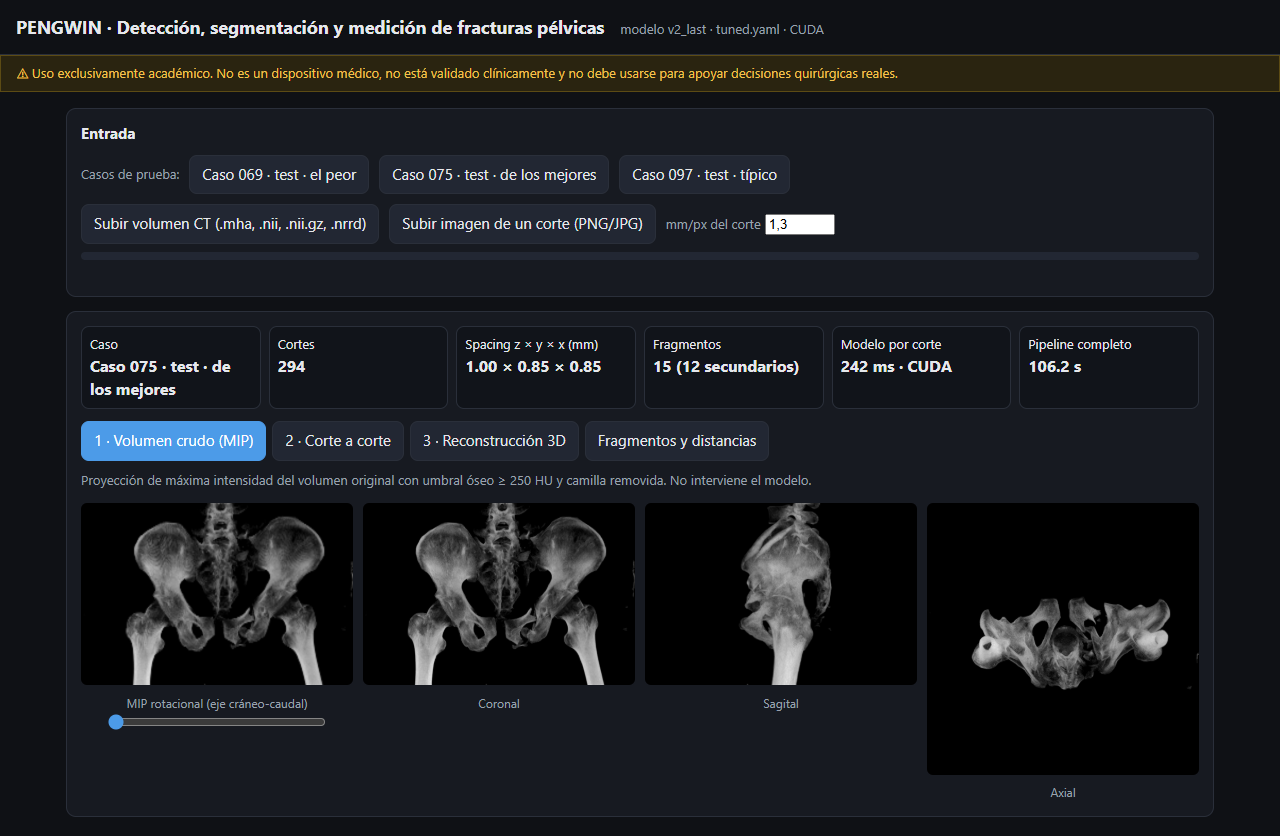

**Visualizador 2: corte a corte con slider; cajas del grid + NMS, máscara por fragmento y distancia escrita**

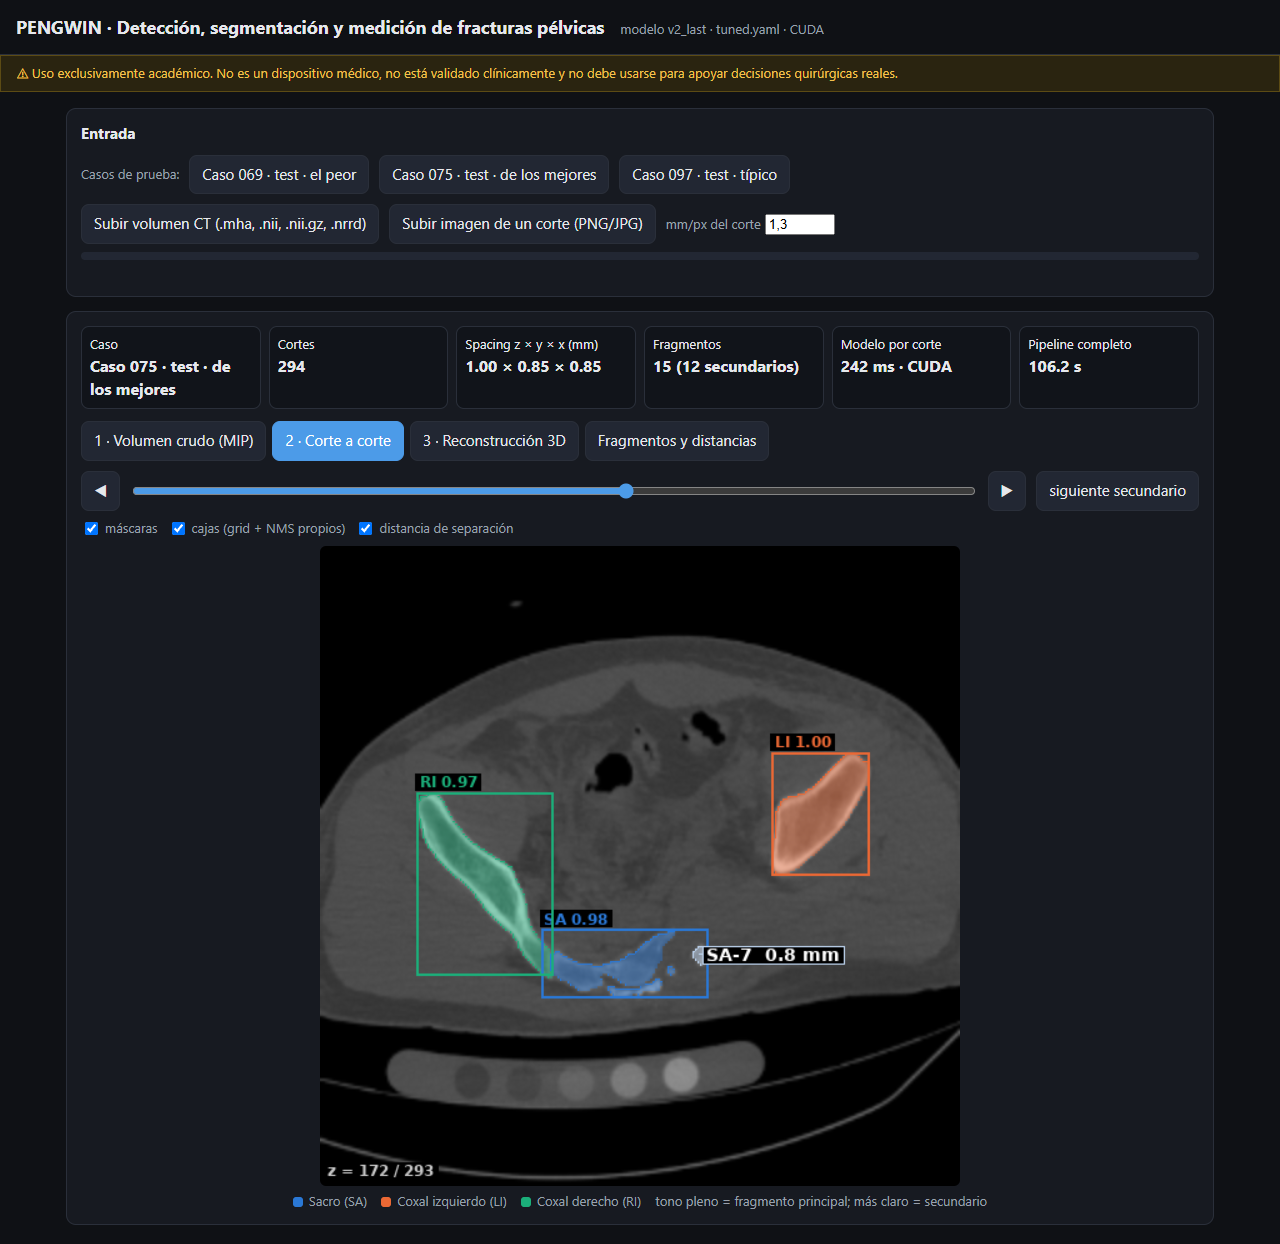

**Visualizador 3: marching cubes + Plotly Mesh3d, distancia junto a cada secundario**

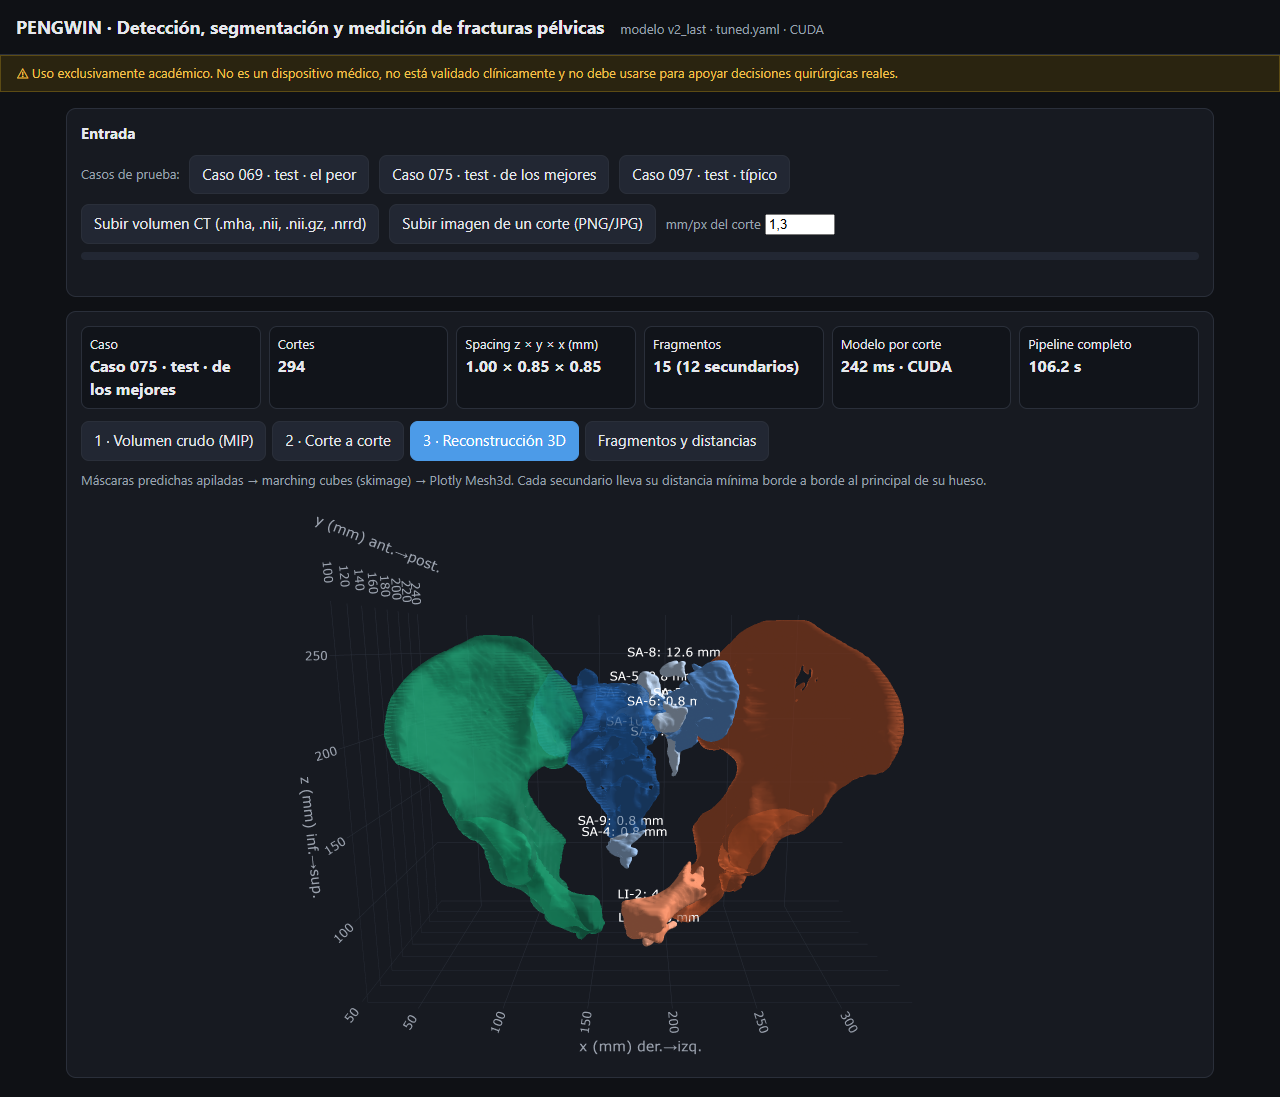

In [2]:
for v, t in (("v1", "Visualizador 1: MIP del volumen crudo (umbral ≥ 250 HU, sin modelo)"),
             ("v2", "Visualizador 2: corte a corte con slider; cajas del grid + NMS, máscara por fragmento y distancia escrita"),
             ("v3", "Visualizador 3: marching cubes + Plotly Mesh3d, distancia junto a cada secundario")):
    display(Markdown(f"**{t}**"))
    display(Image(filename=str(FIG / f"dashboard_{v}.png"), width=820))

La distancia de separación se ve directamente en los visualizadores 2 y 3, no solo en una tabla (§3.4). La cuarta pestaña lista los fragmentos y, en los casos de ejemplo, la distancia real contra la predicha.


### 1.1 Un hueco en el ala ilíaca que no es una fractura

En la reconstrucción 3D del caso 075 el coxal izquierdo sale con un hueco en el ala ilíaca. No es una fractura: una fractura deja fragmentos, no un agujero. Tampoco es sobreajuste. Viene de la resolución:

- En esa zona el ala mide entre 0,85 y 1,7 mm de grosor en la etiqueta de los expertos, con 230-500 HU: es hueso.
- En el 075 un píxel del modelo mide 1,36 mm (la mediana de los 100 casos es 1,27 mm). Al pasar la etiqueta a la grilla de 256 px (vecino más cercano), ese puente se pierde: **la referencia en 256 ya tiene el hueco**. A resolución nativa no lo tiene.
- El modelo aprende de esas etiquetas de 256 y lo reproduce.
- El visualizador 3 lo agrandaba: suavizaba la máscara con un gaussiano σ = 0,8 antes de marching cubes, y con eso una lámina de 1 vóxel queda por debajo de 0,5 y desaparece de la malla.

`scripts/huecos_remuestreo.py` cuenta los túneles (agujeros pasantes) del fragmento principal de cada hueso en los 100 casos, en la etiqueta nativa y en la misma etiqueta en 256 px. Túneles = objetos + cavidades − característica de Euler.

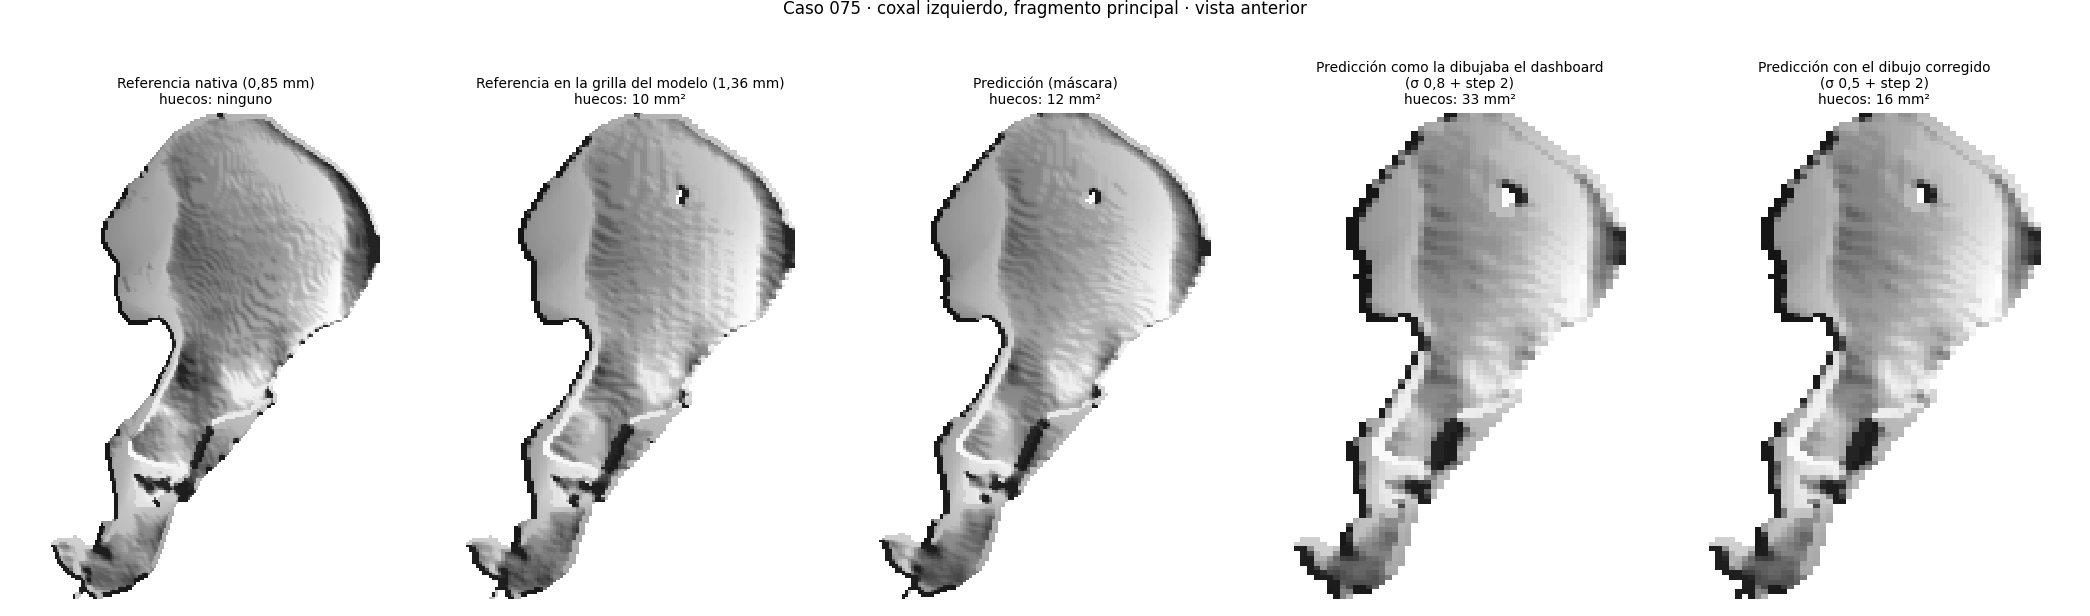

,fragmentos principales,con túneles de más en 256,túneles (nativo),túneles (256 px)
sacro,100,34,2027,2053
coxal izq.,100,36,162,259
coxal der.,100,32,158,231
los tres,300,102,2347,2543


075 · grosor del ala donde aparece el hueco: 0.85-1.71 mm · HU 232-501 · píxel del modelo 1.364 mm


In [3]:
hr = read_json(REP / "eval" / "huecos_remuestreo.json")
display(Image(filename=str(FIG / "hueco_075.png"), width=1000))
t = pd.DataFrame(hr["resumen"]).T.rename(index={"SA": "sacro", "LI": "coxal izq.", "RI": "coxal der.", "todos": "los tres"})
display(t[["principales", "con_tuneles_de_mas_en_256", "tuneles_nativo", "tuneles_256"]].rename(columns={
    "principales": "fragmentos principales", "con_tuneles_de_mas_en_256": "con túneles de más en 256",
    "tuneles_nativo": "túneles (nativo)", "tuneles_256": "túneles (256 px)"}))
e = hr["caso_ejemplo"]
print(f"075 · grosor del ala donde aparece el hueco: {e['grosor_ala_en_el_hueco_mm']['minimo']}-{e['grosor_ala_en_el_hueco_mm']['mediana']} mm "
      f"· HU {e['hu_del_ala_en_el_hueco']['p10']}-{e['hu_del_ala_en_el_hueco']['max']} · píxel del modelo {e['pixel_mm_modelo']} mm")

- **No es un caso aislado:** 102 de los 300 fragmentos principales (34 %) ganan túneles al pasar a 256 px. En los coxales se ve claro (162 → 259 y 158 → 231 túneles). En el sacro los forámenes son túneles reales y el remuestreo abre unos y cierra otros (2027 → 2053).
- **Al Dice casi no le afecta:** el hueco del 075 son unos 12 mm² de una lámina de ~1,5 mm, menos de 0,1 cm³ en un fragmento de 305 cm³.
- **Qué se cambió:** el visualizador 3 suaviza ahora con σ = 0,5 (`05_app/servicio.py`). En una emulación del dibujo sobre vóxeles (`huecos_remuestreo.py`) el hueco del 075 pasa de 33 a 16 mm²; en la malla real del dashboard mide 29 mm² (sección 1.2). La malla pesa lo mismo (~3 MB). No se rellenan huecos a mano: la malla tiene que mostrar la máscara predicha, que es lo que se mide.
- **Qué no se arregla sin cambiar la resolución:** el hueco está en la etiqueta con la que se entrena. Quitarlo pide etiquetas a más resolución o un remuestreo que conserve las láminas delgadas, y eso cambia el caché y obliga a reentrenar. La sección 1.2 mide si un cierre en el posproceso lo arregla. Es el mismo límite de resolución (~1,3 mm por píxel; 1,36 en el 075) que, como hipótesis, le impide a la cabeza de borde ver las grietas más finas entre fragmentos en contacto (sección 8.2).

### 1.2 ¿Se puede cerrar el hueco en el posproceso?

Probamos cerrarlo sin reentrenar. `postprocess.fill_holes_mm` aplica a cada fragmento un cierre morfológico (dilatación y luego erosión) con una bola de ese radio y solo añade vóxeles de fondo, así que no le quita nada a ningún fragmento (`instances.fill_thin_holes`).

- **Datos:** las mismas predicciones fuera de fold con las que se eligió `tuned.yaml` (85 casos de train+val, 5 folds, dos semillas). Las métricas se calculan contra la etiqueta nativa, que no tiene el hueco. El test no se toca (`scripts/rellenar_huecos.py`).
- **Regla, fijada antes de correr:** se adopta el radio más pequeño que no baje el Dice ni el IoU por fragmento más de 0,002 y que deje en la mitad o menos los túneles de más de los coxales (predicción contra etiqueta nativa).
- Los radios de 1,5, 2 y 3 mm estaban en la regla. Los de 5 y 7 mm (solo coxales) se añadieron después, al ver que el hueco del 075 solo se cierra con 7 mm.

In [4]:
ORDEN = ["sin cierre", "r 1.5 mm", "r 2 mm", "r 2 mm coxales", "r 3 mm", "r 3 mm coxales", "r 5 mm coxales", "r 7 mm coxales"]
filas = []
for semilla, archivos in (("42", ("relleno_huecos_base.json", "relleno_huecos_r57_base.json")),
                          ("1337", ("relleno_huecos_s1337.json", "relleno_huecos_r57_s1337.json"))):
    for a in archivos:
        for var, t in read_json(REP / "eval" / a)["variantes"].items():
            if var == "sin cierre" and "r57" in a:
                continue
            filas.append({"semilla": semilla, "cierre": var, "Dice frag": f'{t["dice_fragmento"]:.4f}',
                          "Δ Dice": f'{t["delta_dice_fragmento"]:+.4f}', "folds a favor": f'{t["folds_dice_a_favor"]}/5',
                          "Δ IoU": f'{t["delta_iou_fragmento"]:+.4f}', "cm³ añadidos por caso": round(t["añadido_cm3_por_caso"], 1),
                          "túneles de más (coxales)": t["tuneles_LI"]["de_mas"] + t["tuneles_RI"]["de_mas"],
                          "túneles de menos (sacro)": t["tuneles_SA"]["de_menos"]})
tc = pd.DataFrame(filas)
tc["cierre"] = pd.Categorical(tc["cierre"], ORDEN, ordered=True)
display(tc.sort_values(["semilla", "cierre"]).set_index(["semilla", "cierre"]))

Dice frag   Δ Dice folds a favor    Δ IoU  cm³ añadidos por caso  túneles de más (coxales)  túneles de menos (sacro)
semilla cierre                                                                                                                             
1337    sin cierre        0.7750  +0.0000           0/5  +0.0000                    0.0                       214                       597
        r 1.5 mm          0.7747  -0.0003           0/5  -0.0004                    1.7                       128                       737
        r 2 mm            0.7743  -0.0007           0/5  -0.0012                    3.5                       119                       817
        r 2 mm coxales    0.7746  -0.0004           0/5  -0.0006                    1.3                       119                       597
        r 3 mm            0.7727  -0.0023           0/5  -0.0037                    8.2                       106                      1100
        r 3 mm coxales    0.7741  -0.0009           0/5  -0.0014                    2.4                       106                       597
        r 5 mm coxales    0.7728  -0.0022           0/5  -0.0035                    4.8                       114                       597
        r 7 mm coxales    0.7716  -0.0035           0/5  -0.0056                    7.4                       113                       597
42      sin cierre        0.7860  +0.0000           0/5  +0.0000                    0.0                       192                       573
        r 1.5 mm          0.7858  -0.0002           0/5  -0.0003                    1.7                       123                       746
        r 2 mm            0.7854  -0.0006           0/5  -0.0010                    3.5                       122                       828
        r 2 mm coxales    0.7857  -0.0003           1/5  -0.0004                    1.2                       122                       573
        r 3 mm            0.7838  -0.0022           0/5  -0.0034                    8.0                       122                      1056
        r 3 mm coxales    0.7852  -0.0008           0/5  -0.0012                    2.3                       122                       573
        r 5 mm coxales    0.7839  -0.0021           0/5  -0.0032                    4.6                       126                       573
        r 7 mm coxales    0.7825  -0.0035           0/5  -0.0054                    7.1                       136                       573

- **Todos los radios bajan el Dice y el IoU por fragmento**, en todos los folds de las dos semillas (0/5 a favor; una sola vez 1/5). De 1,5 a 3 mm la pérdida es de −0,0002 a −0,0023; con 5 y 7 mm en los coxales llega a −0,0035. Lo que se gana tapando huecos se pierde rellenando concavidades que en la etiqueta nativa no son hueso.
- **Los túneles de más de los coxales bajan entre un 30 y un 50 %, pero no desaparecen.** Con radios grandes vuelven a subir, porque el cierre también crea puentes nuevos.
- **En el sacro cierra forámenes reales:** los túneles que le faltan a la predicción pasan de ~590 a 740-1100. Por eso se probó también solo en los coxales.

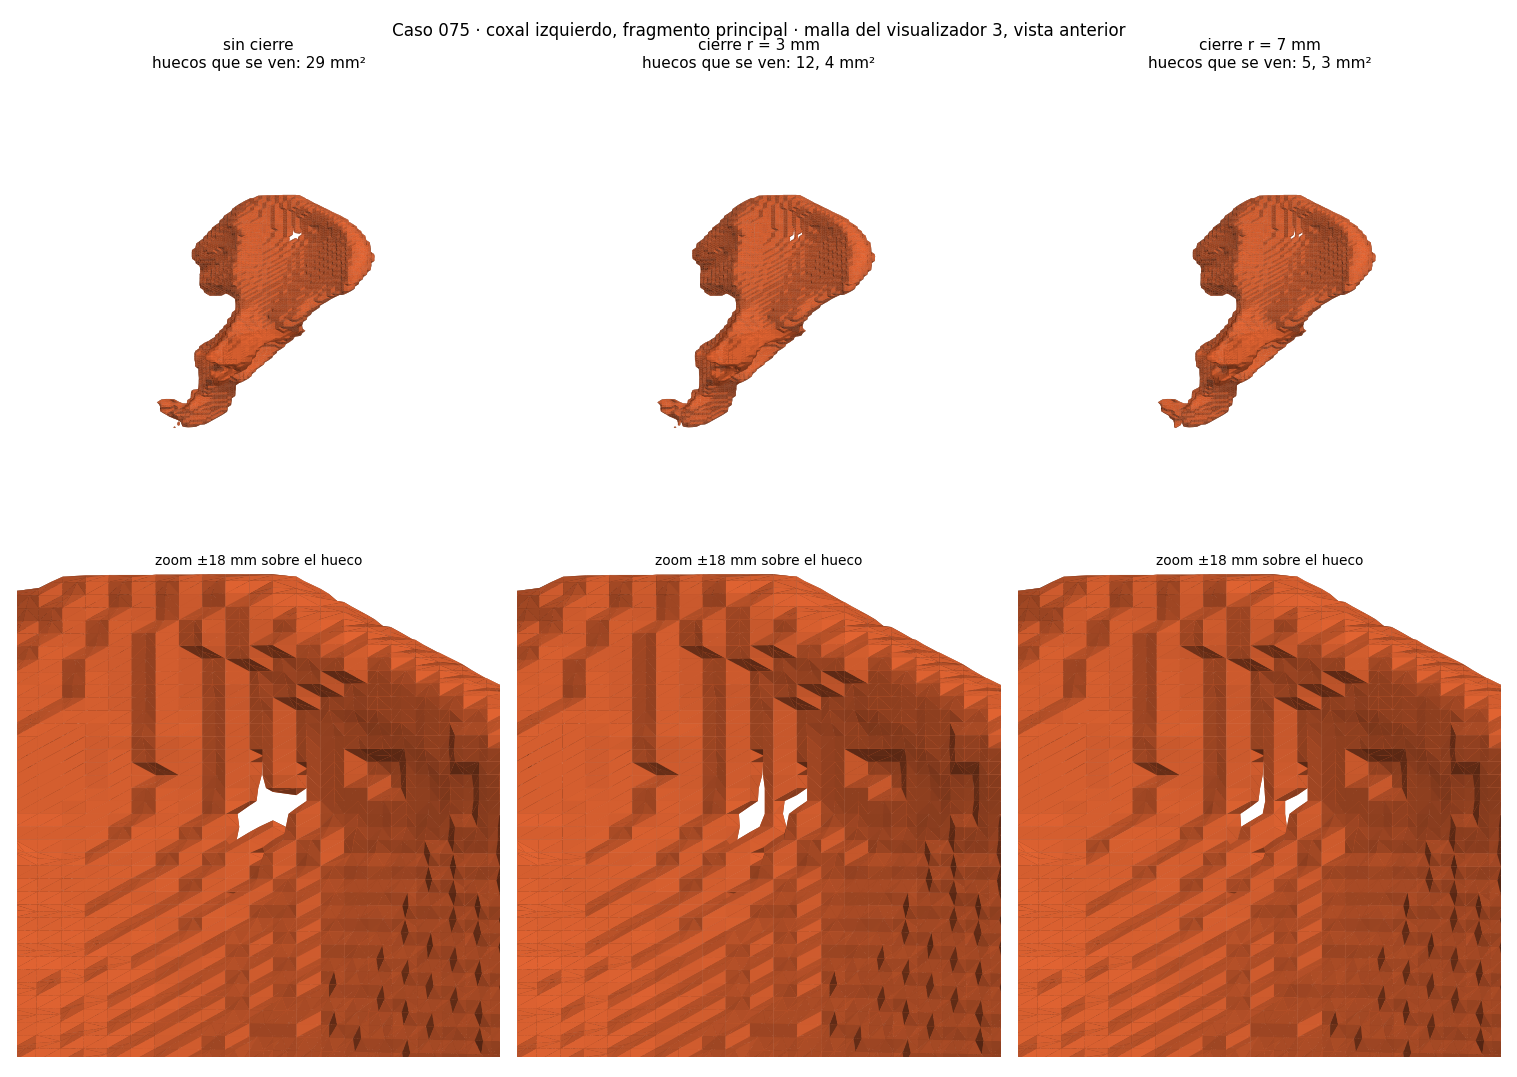

r = 0 mm · túneles del principal 1 · huecos que se ven en la malla [29.0] mm² · cierre 0.0 s · malla 3.03 MB
r = 3 mm · túneles del principal 1 · huecos que se ven en la malla [11.5, 4.2] mm² · cierre 0.6 s · malla 3.02 MB
r = 7 mm · túneles del principal 0 · huecos que se ven en la malla [5.0, 3.2] mm² · cierre 4.82 s · malla 3.02 MB


In [5]:
display(Image(filename=str(FIG / "relleno_075.png"), width=1000))
for v in read_json(REP / "eval" / "relleno_visualizador_075.json")["variantes"]:
    print(f"r = {v['radio_mm']:g} mm · túneles del principal {v['tuneles_principal']} · huecos que se ven en la malla "
          f"{v['huecos_vistos_mm2'] or 'ninguno'} mm² · cierre {v['segundos_cierre']} s · malla {v['malla_mb']} MB")

- **En el visualizador** (caso 075, malla hecha con la misma función del dashboard): con 3 mm el hueco pasa de 29 mm² a dos rendijas de 12 y 4 mm². Con 7 mm la máscara queda sin túnel, pero la malla todavía muestra rendijas de 5 y 3 mm², porque el puente que cierra el hueco es una lámina unida solo en diagonal. El cierre tarda unos segundos por caso y no cambia el peso de la malla.
- **Decisión: no se adopta.** Ningún radio cumple la regla en las dos semillas. El hueco se puede achicar, pero no quitar sin bajar las métricas. Quitarlo de raíz pide etiquetas a más resolución, o un remuestreo que conserve las láminas delgadas, y reentrenar: queda como trabajo futuro. `fill_holes_mm` queda en el código con 0 por defecto, así que nada cambia.

## 2. Entrada robusta: orientación por metadatos

En el avance del 9 de octubre el profesor insistió en orientar los volúmenes con los metadatos (vectores de dirección del header), no con rotaciones a ojo. Así se hace:

1. `SimpleITK.DICOMOrient(img, "LPS")` permuta y voltea los ejes según los cosenos directores, sin interpolar. En PENGWIN, 66 volúmenes vienen en LPS y 34 en RAS; los 34 quedan en LPS.
2. **Nuevo en esta semana:** si después de eso queda una rotación residual (gantry inclinado), `align_to_axes` remuestrea el volumen a la grilla LPS alineada con los ejes, calculando la caja nueva a partir de las 8 esquinas en coordenadas físicas: $p = o + D \cdot \mathrm{diag}(s) \cdot i$. Imagen con interpolación lineal; etiqueta con vecino más cercano, para no inventar ids.

Ninguno de los 100 casos de PENGWIN es oblicuo (se revisó el header de todos), pero el volumen que se suba al dashboard sí puede serlo. Lo verifican tres tests en `06_tests/test_semana11.py`: un volumen alineado no se toca, una esfera en un volumen girado 12° queda en el mismo punto físico (< 1 mm) y una etiqueta girada 20° conserva sus ids.

Las aumentaciones del entrenamiento (rotación ±10°, escala 0,9-1,1) son otra cosa: simulan variación entre pacientes después de orientar, no corrigen la orientación.

## 3. Latencia en CPU y GPU

Un corte a la vez (como en el slider), contando modelo, decodificación de cajas y NMS. Equipo de medición: laptop con RTX 3060 y CPU Intel i7-11800H (8 núcleos), medida con 8 hilos de PyTorch.

In [6]:
filas = {}
for k, f in (("sin TTA", "v2_last.json"), ("con TTA 5 (final)", "v2_last_tta.json")):
    l = read_json(REP / "latency" / f)
    filas[k] = {"CPU fp32 (ms)": l["cpu_fp32"]["media_ms"], "CPU p95 (ms)": l["cpu_fp32"]["p95_ms"],
                "GPU fp32 (ms)": l["gpu_fp32"]["media_ms"], "GPU AMP (ms)": l["gpu_amp"]["media_ms"],
                "volumen GPU (s)": l["gpu_volumen_completo_s"], "cortes": l["cortes_volumen"]}
lat = pd.DataFrame(filas).T
display(lat.round(1))
print(f"GPU: {l['gpu']} · CPU: {l['cpu']}, {l['torch_threads']} hilos")

,CPU fp32 (ms),CPU p95 (ms),GPU fp32 (ms),GPU AMP (ms),volumen GPU (s),cortes
sin TTA,66.2,78.5,7.7,10.3,2.8,401.0
con TTA 5 (final),308.6,358.6,33.8,37.9,7.4,401.0


GPU: NVIDIA GeForce RTX 3060 Laptop GPU · CPU: Intel64 Family 6 Model 141 Stepping 1, GenuineIntel, 8 hilos


- La GPU es ~9 veces más rápida que la CPU. Con TTA cada corte cuesta 5 pasadas: ×4,4 en GPU y ×4,7 en CPU.
- En GPU, AMP no acelera con batch 1 (el modelo es pequeño, 2,9 M de parámetros, y domina el costo fijo de lanzar kernels); se mantiene por el enunciado y porque sí ayuda al entrenar con batch 8.
- El volumen completo en GPU (7,4 s con TTA) es lo que espera el usuario del dashboard; el resto del pipeline (fragmentos, grilla nativa, malla) suma unos segundos más.

## 4. Matriz de confusión

Modelo final sobre los 15 pacientes de test. Dos matrices: la **clasificación por corte** (¿está el hueso en el corte?), y la **segmentación por píxel** (qué hueso es cada píxel), en la grilla del modelo.

,VP,FN,FP,VN,precisión,recall,F1
SA,2440.0,45.0,44.0,2311.0,0.982,0.982,0.982
LI,3589.0,8.0,4.0,1239.0,0.999,0.998,0.998
RI,3566.0,5.0,3.0,1266.0,0.999,0.999,0.999


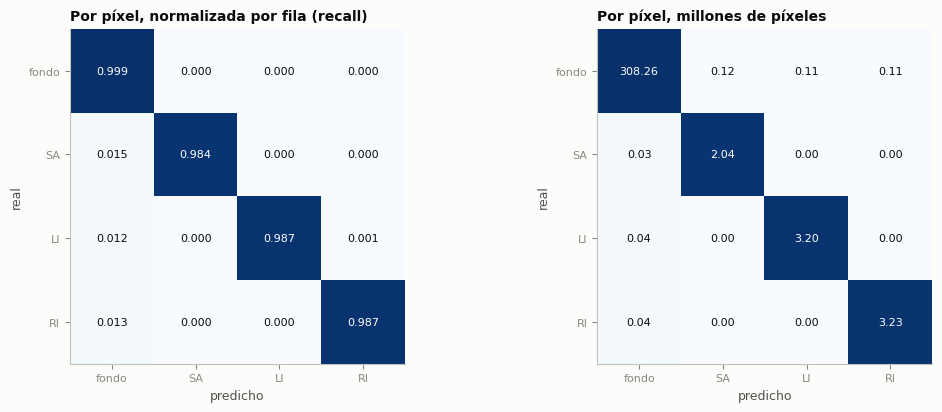

In [7]:
cm = read_json(REP / "eval" / "confusion_test.json")
filas = {}
for h, m in cm["clasificacion_por_corte"].items():
    (tn, fp), (fn, tp) = m
    filas[h] = {"VP": tp, "FN": fn, "FP": fp, "VN": tn, "precisión": tp / (tp + fp), "recall": tp / (tp + fn),
                "F1": 2 * tp / (2 * tp + fp + fn)}
display(pd.DataFrame(filas).T.round(3))

P = np.array(cm["pixeles"]["matriz"], float)
Pn = P / P.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (M, t, f) in zip(axes, ((Pn, "Por píxel, normalizada por fila (recall)", "{:.3f}"),
                               (P / 1e6, "Por píxel, millones de píxeles", "{:.2f}"))):
    ax.imshow(Pn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4), cm["pixeles"]["clases"])
    ax.set_yticks(range(4), cm["pixeles"]["clases"])
    ax.set(xlabel="predicho", ylabel="real")
    ax.set_title(t, loc="left", fontsize=10)
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f.format(M[i, j]), ha="center", va="center", fontsize=8, color="white" if Pn[i, j] > 0.5 else INK)
fig.tight_layout()
savefig(fig, "confusion")
plt.show()

- **Entre huesos casi no hay confusión:** confundir sacro con un coxal, o un coxal con el otro, es el 0,06 % de los píxeles de hueso. La lateralidad (LI contra RI) es correcta, que era el riesgo de los 34 volúmenes en RAS.
- **El error que queda es contra el fondo:** 1,2-1,5 % de los píxeles de hueso salen como fondo (bordes finos, ramas delgadas). El sacro es la clase con menos recall (0,984): es el hueso más irregular y con más fragmentos pequeños.
- **Por corte**, la clasificación falla casi solo en los extremos del hueso, donde aparece o desaparece en unos pocos píxeles: 45 FN y 44 FP del sacro sobre 4 840 cortes.

## 5. Los cinco peores casos

Los cinco pacientes con menor Dice por fragmento. Para cada secundario real que no se recuperó (IoU < 0,5) se midió qué hizo el modelo en **sus** vóxeles: si quedaron dentro del principal (*absorbido*), en otro fragmento (*partido*), en otro hueso o en el fondo (`scripts/peores_casos.py`).

In [8]:
pc = read_json(REP / "eval" / "peores_casos.json")
filas = []
for cid, d in pc.items():
    for p in d["secundarios_perdidos"]:
        filas.append({"paciente": cid, "Dice frag del caso": d["dice_fragmento"], "fragmentos real / pred": f"{d['n_gt']} / {d['n_pred']}",
                      "secundario perdido": p["fragmento"], "volumen cm³": p["volumen_cm3"], "IoU": p["iou"],
                      "en contacto (GT)": "sí" if p["en_contacto"] else "no", "qué pasó": p["que_paso"],
                      "fracción": p["fraccion"]})
tab = pd.DataFrame(filas)
display(tab.round(3))
print(f"{len(tab)} secundarios perdidos · en contacto con su principal: {(tab['en contacto (GT)'] == 'sí').sum()} · "
      f"absorbidos: {(tab['qué pasó'] == 'absorbido').sum()} · partidos: {(tab['qué pasó'] == 'partido').sum()} · "
      f"sin hueso: {(tab['qué pasó'] == 'sin hueso').sum()}")

,paciente,Dice frag del caso,fragmentos real / pred,secundario perdido,volumen cm³,IoU,en contacto (GT),qué pasó,fracción
0,069,0.536,7 / 19,SA-2,8.43,0.000,sí,absorbido,0.97
1,069,0.536,7 / 19,LI-2,11.11,0.000,sí,absorbido,0.95
2,069,0.536,7 / 19,LI-3,15.99,0.044,sí,absorbido,0.93
3,011,0.599,6 / 28,LI-2,94.98,0.484,sí,partido,0.49
4,011,0.599,6 / 28,LI-3,3.77,0.013,sí,sin hueso,0.84
5,011,0.599,6 / 28,RI-2,38.16,0.068,sí,absorbido,0.82
6,056,0.614,6 / 17,RI-2,12.48,0.017,sí,absorbido,0.92
7,056,0.614,6 / 17,RI-4,5.18,0.000,sí,absorbido,0.84
8,010,0.683,5 / 17,LI-3,71.34,0.000,sí,absorbido,0.98
9,080,0.723,4 / 16,SA-2,40.29,0.067,sí,absorbido,0.90


10 secundarios perdidos · en contacto con su principal: 10 · absorbidos: 8 · partidos: 1 · sin hueso: 1


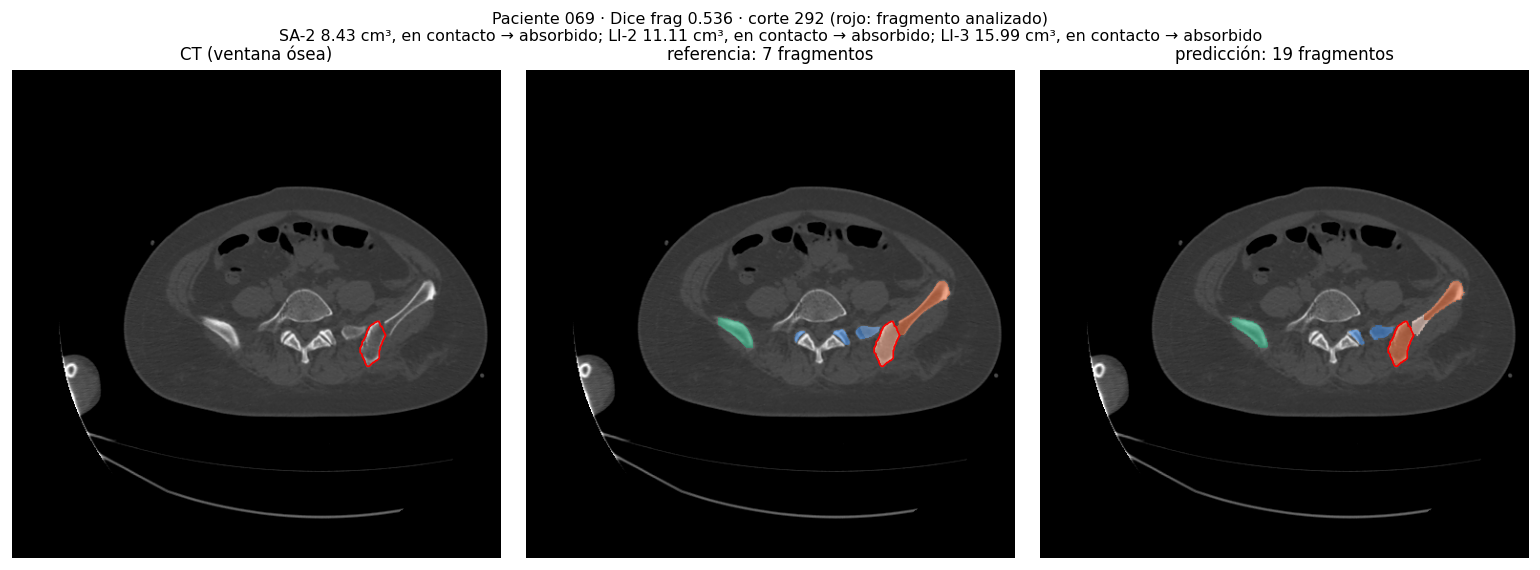

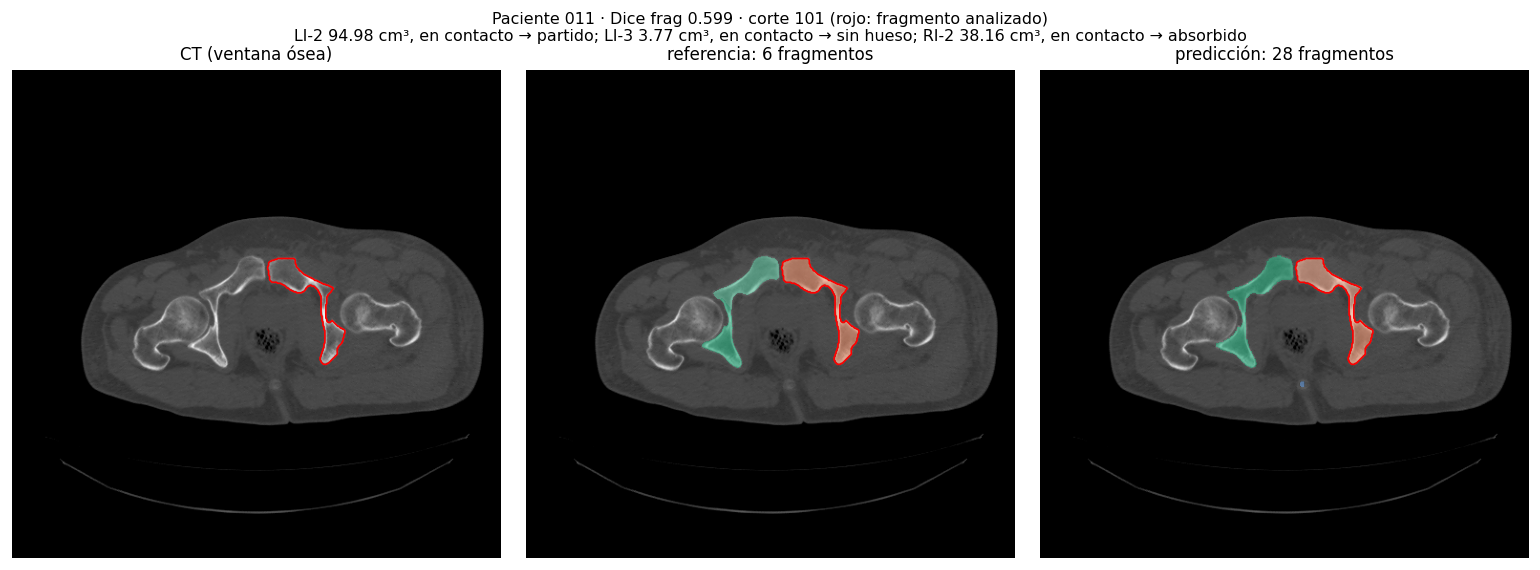

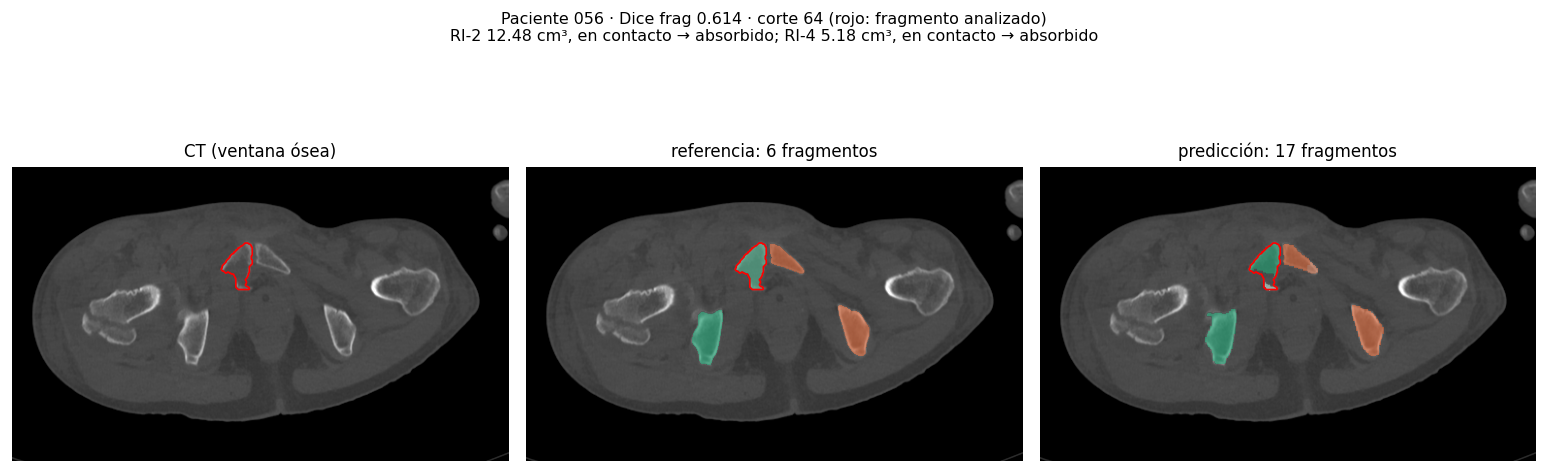

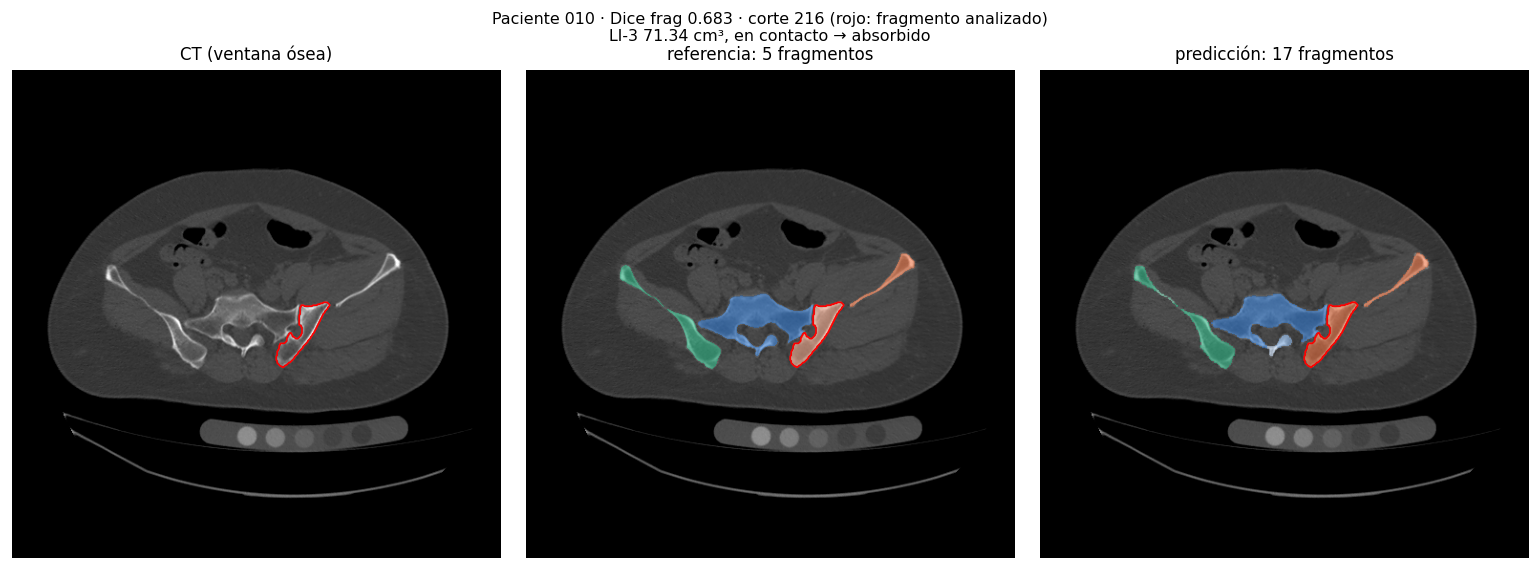

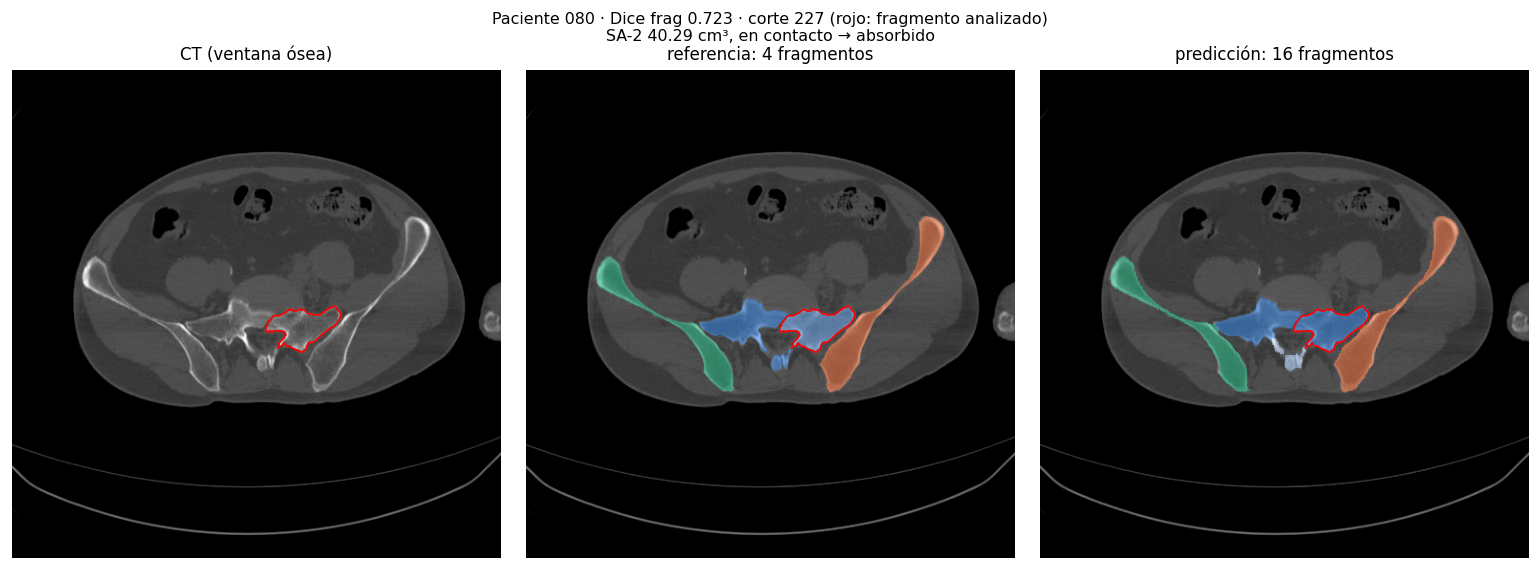

In [9]:
for cid in pc:
    display(Image(filename=str(FIG / f"peor_{cid}.png"), width=900))

**Hipótesis, sostenidas por la tabla:**

1. **Fragmentos en contacto que se fusionan (8 de 10).** Todos los secundarios perdidos tocan al principal en el GT (distancia ≤ diagonal del vóxel, ~1,5 mm). Si la cabeza de borde no marca la superficie de fractura, el núcleo no se corta y la semilla del principal se extiende al secundario. Es la limitación que el enunciado pide declarar en el model card, y coincide con lo que mostró el oráculo de la semana 10: con el borde real el Dice por fragmento subiría a 0,90 en validación cruzada.
2. **Un fragmento grande cortado por otro sitio (paciente 011, LI-2, 95 cm³).** El modelo encontró dos fragmentos, pero la separación no coincide con la fractura real: IoU 0,48, casi recuperado.
3. **Un fragmento pequeño que no se segmenta (011, LI-3, 3,8 cm³).** La región predicha lo deja como fondo: el 1,2-1,5 % de recall perdido de la sección 4 se concentra en piezas así.
4. **Los principales están bien en los cinco** (Dice 0,88-0,93): el error es de separación, no de detección del hueso.
5. **Fragmentos de más:** en estos cinco casos, 16 a 28 predichos contra 4 a 7 reales. No restan en el Dice por fragmento (se promedia sobre los reales), pero sí se ven en la reconstrucción 3D.

## 6. Distancia de separación: predicción contra referencia

La misma medida en la predicción y en el ground truth (§3.3), para cada secundario real que el modelo recuperó (IoU ≥ 0,5).

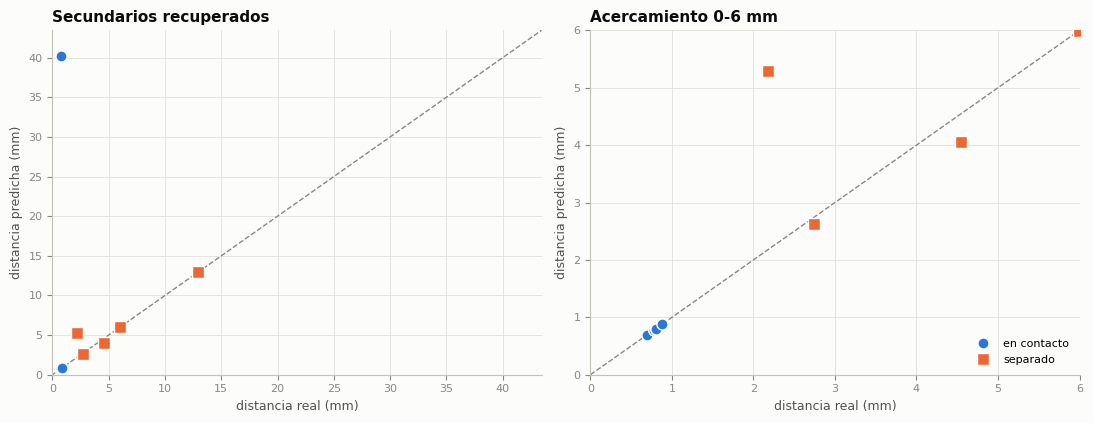

,count,mean,median,max
separado,5,0.75,0.11,3.12
en contacto,17,2.32,0.00,39.42


Secundarios reales: 39 · con distancia comparable: 22 (56 %) · error medio 1.96 mm · mediana 0.00 mm


In [10]:
d = pd.read_csv(REP / "fragments" / "v2_last_test_tuned_superficie_distancias.csv")
dm = d[d.medido]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
lim = max(dm.dist_gt_mm.max(), dm.dist_pred_mm.max()) * 1.08
for ax, l in zip(axes, (lim, 6)):
    ax.plot([0, l], [0, l], color=MUTED, lw=1, ls="--")
    for contacto, mk, nombre in ((True, "o", "en contacto"), (False, "s", "separado")):
        s = dm[dm.contacto_gt == contacto]
        ax.plot(s.dist_gt_mm, s.dist_pred_mm, mk, ms=8, color=C["SA"] if contacto else C["LI"], mec="white", ls="none", label=nombre)
    ax.set(xlabel="distancia real (mm)", ylabel="distancia predicha (mm)", xlim=(0, l), ylim=(0, l))
axes[0].set_title("Secundarios recuperados", loc="left")
axes[1].set_title("Acercamiento 0-6 mm", loc="left")
axes[1].legend()
fig.tight_layout()
savefig(fig, "distancias")
plt.show()
res = dm.assign(err=dm.error_mm.abs()).groupby("contacto_gt").err.agg(["count", "mean", "median", "max"])
res.index = ["separado" if not i else "en contacto" for i in res.index]
display(res.round(2))
print(f"Secundarios reales: {len(d)} · con distancia comparable: {len(dm)} ({100 * len(dm) / len(d):.0f} %) · "
      f"error medio {dm.error_mm.abs().mean():.2f} mm · mediana {dm.error_mm.abs().median():.2f} mm")

- La mayoría de los puntos cae sobre la diagonal: cuando el modelo recupera el fragmento, la distancia sale casi igual que en la referencia (mediana del error 0 mm).
- El error medio lo dominan pocos casos donde el **principal** se partió: el secundario se mide contra el pedazo equivocado. Así se transfiere un error de segmentación a la medida, que es lo que pedía observar el §3.3.
- La limitación es la cobertura: solo el 56 % de los secundarios reales se recupera y se puede medir.

## 7. HD95 y ASSD (extensión opcional del §5)

Distancias entre superficies para cada pareja (fragmento real, fragmento predicho) del emparejamiento húngaro, con el spacing del header: HD95 es el percentil 95 de las distancias de cada punto de una superficie a la otra, en los dos sentidos, y ASSD su media.

In [11]:
f = pd.read_csv(REP / "fragments" / "v2_last_test_tuned_superficie_fragmentos.csv")
f["tipo"] = np.where(f.es_principal, "principal", "secundario")
f["tamaño"] = pd.cut(f.volumen_cm3, [0, 5, 20, np.inf], labels=["< 5 cm³", "5-20 cm³", "> 20 cm³"])
emp = f.dropna(subset=["hd95_mm"])
display(emp.groupby("tipo").agg(n=("hd95_mm", "size"), Dice=("dice", "mean"), HD95_mm=("hd95_mm", "mean"),
                                HD95_mediana=("hd95_mm", "median"), ASSD_mm=("assd_mm", "mean")).round(2))
display(emp.groupby("tamaño", observed=True).agg(n=("hd95_mm", "size"), Dice=("dice", "mean"), HD95_mm=("hd95_mm", "mean"),
                                                 ASSD_mm=("assd_mm", "mean")).round(2))
print(f"Global (parejas con IoU > 0): HD95 {G['hd95_mm']:.1f} mm · ASSD {G['assd_mm']:.1f} mm · "
      f"{f.hd95_mm.isna().sum()} fragmentos reales sin pareja no entran")

,n,Dice,HD95_mm,HD95_mediana,ASSD_mm
tipo,,,,,
principal,45,0.92,6.90,3.03,1.24
secundario,34,0.67,18.11,8.54,6.11


,n,Dice,HD95_mm,ASSD_mm
tamaño,,,,
< 5 cm³,6,0.61,8.56,3.06
5-20 cm³,10,0.60,21.85,7.30
> 20 cm³,63,0.87,10.42,2.73


Global (parejas con IoU > 0): HD95 11.7 mm · ASSD 3.3 mm · 5 fragmentos reales sin pareja no entran


- Los principales quedan cerca de la referencia: ASSD 1,2 mm y HD95 mediano 3,0 mm. La media del HD95 (6,9 mm) la suben pocos casos donde la zona de fractura quedó mal cortada.
- En los secundarios el HD95 es mucho mayor (media 18,1 mm, mediana 8,5 mm): cuando la pareja existe pero está mal cortada, parte de su superficie queda lejos. El Dice lo castiga menos porque premia el volumen que sí coincide.
- Sirve como referencia frente al challenge, que reporta estas métricas en 3D con modelos volumétricos; aquí son de un modelo 2D corte a corte.

## 8. Lo que pidió el profesor

| Pedido (avance) | Dónde se responde |
|---|---|
| Evolución de γ en cada capa con CBAM, por época (2-oct) | 8.1 |
| Train contra val con la misma métrica (2-oct) | 8.2 |
| Grad-CAM con y sin atención (2-oct) | 8.3 |
| Dropout espacial de 15-20 % (2-oct) | barrido de 0 a 0,40 en `02_semana10` §17: sin efecto medible, se queda 0,1 |
| ¿Dice volumétrico o corte a corte? (9-oct) | volumétrico: Dice e IoU por fragmento en 3D sobre la grilla nativa |
| Rotaciones por metadatos (9-oct) | sección 2 |
| Entrenar por etapas y afinar la segmentación con el detector apagado; cuidado con la EMA (9-oct) | sección 9 |

### 8.1 γ por época

`v2_repro` repite el entrenamiento `v2` (misma configuración, semilla y λ) registrando por época los γ de los dos CBAM y del cuello.

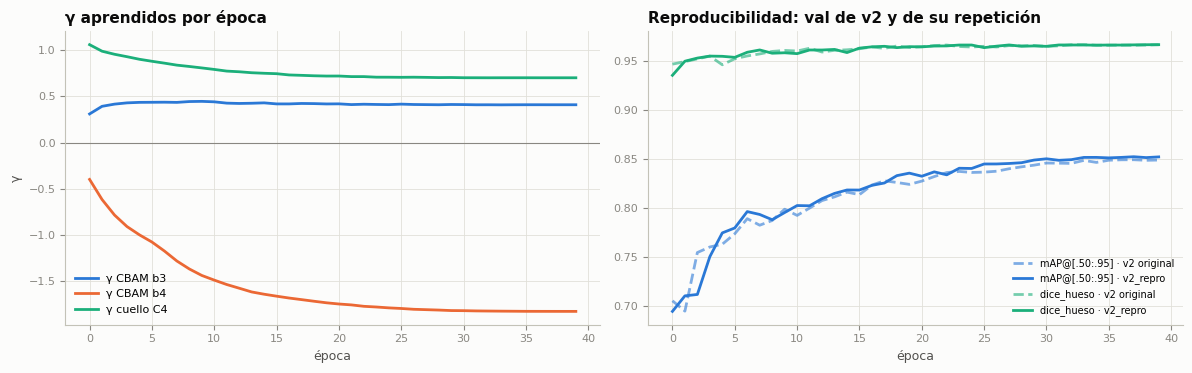

,epoch,gamma residual b1,gamma residual b2,gamma residual b3,gamma CBAM b3,gamma residual b4,gamma CBAM b4,gamma cuello C4
0,0,0.078,0.074,0.085,0.309,0.168,-0.399,1.058
4,4,0.163,0.145,0.139,0.434,0.242,-0.998,0.900
9,9,0.198,0.178,0.165,0.445,0.282,-1.437,0.807
19,19,0.231,0.210,0.193,0.417,0.314,-1.732,0.719
29,29,0.239,0.221,0.204,0.411,0.327,-1.816,0.703
39,39,0.240,0.223,0.207,0.409,0.329,-1.825,0.700


In [12]:
hr = REP / "train" / "v2_repro_history.csv"
H2 = pd.read_csv(REP / "train" / "v2_history.csv")
if not hr.exists():
    print("Pendiente: v2_repro todavía está entrenando en la DGX Spark.")
    HR = None
else:
    HR = pd.read_csv(hr)
    gcols = [c for c in HR.columns if c.startswith("gamma ")]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for c, col in zip(["gamma CBAM b3", "gamma CBAM b4", "gamma cuello C4"], (C["SA"], C["LI"], C["RI"])):
        if c in HR:
            axes[0].plot(HR.epoch, HR[c], color=col, label=c.replace("gamma ", "γ "))
    axes[0].axhline(0, color=MUTED, lw=0.8)
    axes[0].set(xlabel="época", ylabel="γ")
    axes[0].set_title("γ aprendidos por época", loc="left")
    axes[0].legend()
    for c, col in (("mAP@[.50:.95]", C["SA"]), ("dice_hueso", C["RI"])):
        axes[1].plot(H2.epoch, H2[c], color=col, ls="--", alpha=0.6, label=f"{c} · v2 original")
        axes[1].plot(HR.epoch, HR[c], color=col, label=f"{c} · v2_repro")
    axes[1].set(xlabel="época")
    axes[1].set_title("Reproducibilidad: val de v2 y de su repetición", loc="left")
    axes[1].legend(fontsize=7)
    fig.tight_layout()
    savefig(fig, "gammas")
    plt.show()
    display(HR[["epoch"] + gcols].iloc[[0, 4, 9, 19, 29, len(HR) - 1]].round(3))

**Lectura de γ:**

- **CBAM b4** pasa de −0,40 en la primera época a −1,83 al final. En `v2` terminó en −1,90: la inversión de la atención es estable entre corridas.
- **CBAM b3** sube hasta 0,45 hacia la época 9 y queda en 0,41, mientras que en `v2` terminó en 0,18. Que cambie tanto entre dos corridas con la misma semilla (solo difieren en el no determinismo de cuDNN) indica que la pérdida casi no depende de él. Es coherente con que apagarlo no cambie nada.
- **El cuello** baja de 1,06 a 0,70: la red usa el contexto profundo de C4, pero atenuado.
- **Reproducibilidad:** al final, `v2` y su repetición dan en validación mAP@[.50:.95] 0,849 y 0,852, IoU de caja 0,914 y 0,915, Dice de región 0,967 y 0,967, y F1 0,991 y 0,992.

### 8.2 Train contra validación con la misma métrica

En cada época se evalúan también 2000 cortes de train **sin aumentación**, con exactamente las mismas métricas que validación. Así la brecha entre las dos curvas mide sobreajuste, y no la diferencia entre medir con o sin aumentación.

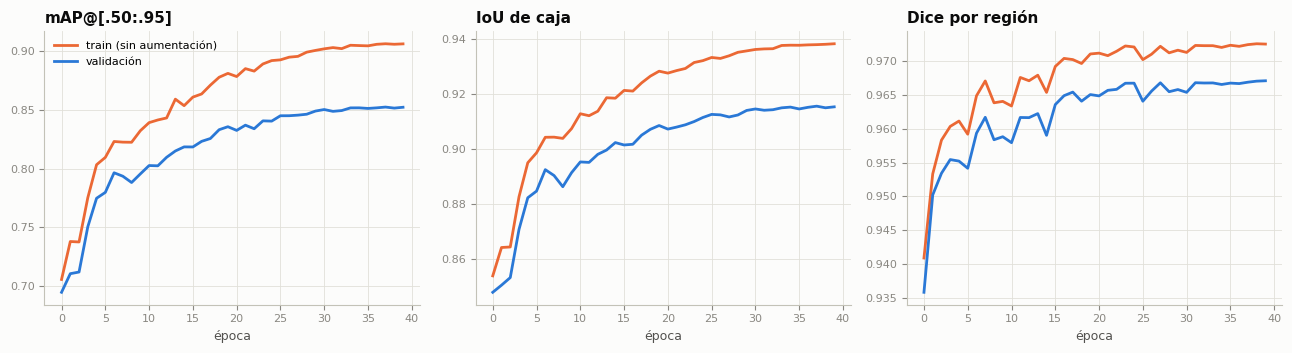

,train,val,brecha
mAP@[.50:.95],0.906,0.852,0.054
IoU de caja,0.938,0.915,0.023
Dice región,0.973,0.967,0.005


In [13]:
if HR is None or "trainset_dice_hueso" not in HR:
    print("Pendiente: v2_repro todavía está entrenando en la DGX Spark.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, (m, t) in zip(axes, (("mAP@[.50:.95]", "mAP@[.50:.95]"), ("IoU_promedio", "IoU de caja"), ("dice_hueso", "Dice por región"))):
        ax.plot(HR.epoch, HR[f"trainset_{m}"], color=C["LI"], label="train (sin aumentación)")
        ax.plot(HR.epoch, HR[m], color=C["SA"], label="validación")
        ax.set_title(t, loc="left")
        ax.set_xlabel("época")
    axes[0].legend()
    fig.tight_layout()
    savefig(fig, "train_vs_val")
    plt.show()
    u = HR.iloc[-1]
    display(pd.DataFrame({"train": [u[f"trainset_{m}"] for m in ("mAP@[.50:.95]", "IoU_promedio", "dice_hueso")],
                          "val": [u[m] for m in ("mAP@[.50:.95]", "IoU_promedio", "dice_hueso")]},
                         index=["mAP@[.50:.95]", "IoU de caja", "Dice región"]).assign(brecha=lambda x: x.train - x.val).round(3))

La brecha es pequeña: 0,054 en mAP@[.50:.95], 0,023 en IoU de caja y 0,005 en Dice de región. Detección y región no sobreajustan. El sobreajuste está en la cabeza de borde (pérdida de borde 0,23 en train contra 0,43 en validación en la CV), que no entra en estas métricas: es la misma conclusión a la que llegan el oráculo y la galería de peores casos.

### 8.3 Grad-CAM con y sin atención

Grad-CAM sobre la salida del bloque 4 (después del CBAM) para la presencia de cada hueso: $\alpha_k = \overline{\partial y_c / \partial A_k}$, $\mathrm{CAM} = \mathrm{ReLU}(\sum_k \alpha_k A_k)$. Se comparan los modelos de la semana 9 **con** y **sin** CBAM (idénticos en lo demás) y el final. La última columna es el mapa de atención espacial $M_s$ del CBAM del modelo final.

**La pérdida del borde sí muestra el sobreajuste.** Las métricas de arriba no incluyen el borde. Su pérdida se registra en las dos particiones en cada época; la de train es la del propio entrenamiento, con aumentación.

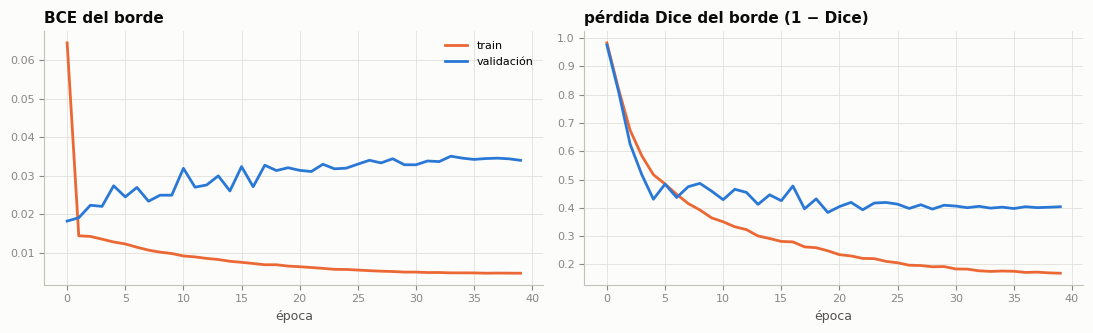

,época 0,mínimo de la BCE en val (época 0),mínimo de la Dice en val (época 19),época 39
BCE train,0.064,0.064,0.006,0.005
BCE val,0.018,0.018,0.032,0.034
Dice train,0.983,0.983,0.248,0.169
Dice val,0.976,0.976,0.383,0.404


In [14]:
if HR is None or "train_edge_bce" not in HR:
    print("Pendiente: v2_repro todavía está entrenando en la DGX Spark.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    for ax, (m, t) in zip(axes, (("edge_bce", "BCE del borde"), ("edge_dice", "pérdida Dice del borde (1 − Dice)"))):
        ax.plot(HR.epoch, HR[f"train_{m}"], color=C["LI"], label="train")
        ax.plot(HR.epoch, HR[f"val_{m}"], color=C["SA"], label="validación")
        ax.set_title(t, loc="left")
        ax.set_xlabel("época")
    axes[0].legend()
    fig.tight_layout()
    savefig(fig, "borde_train_val")
    plt.show()
    kb, kd = int(HR.val_edge_bce.idxmin()), int(HR.val_edge_dice.idxmin())
    filas = {"época 0": HR.iloc[0], f"mínimo de la BCE en val (época {int(HR.epoch[kb])})": HR.iloc[kb],
             f"mínimo de la Dice en val (época {int(HR.epoch[kd])})": HR.iloc[kd], f"época {int(HR.epoch.iloc[-1])}": HR.iloc[-1]}
    display(pd.DataFrame({k: [r.train_edge_bce, r.val_edge_bce, r.train_edge_dice, r.val_edge_dice] for k, r in filas.items()},
                         index=["BCE train", "BCE val", "Dice train", "Dice val"]).round(3))

- La BCE del borde en validación es mínima en la época 0 (0,018) y sube hasta 0,034, mientras la de train baja de 0,064 a 0,005.
- La pérdida Dice del borde en validación mejora hasta la época 19 (0,38) y se queda en ~0,40, mientras la de train sigue bajando hasta 0,17.
- Es el patrón "train baja, validación sube". Contra eso ya se había probado subir la dificultad (aumentación fuerte, `c09`: subajusta), regularizar con dropout (0 a 0,40: nada), congelar el backbone (sección 9: empeora) y frenarlo (`c10`: empeora). Faltaban L2, una cabeza más pequeña y un decodificador con detalle fino (U-Net++, de la sesión 2 de segmentación). Se prueban en la DGX Spark con reglas fijadas antes de correr (`reports/tuning/s11_borde/PREREGISTRO.md`); los resultados van en `04_semana11_borde.ipynb`.

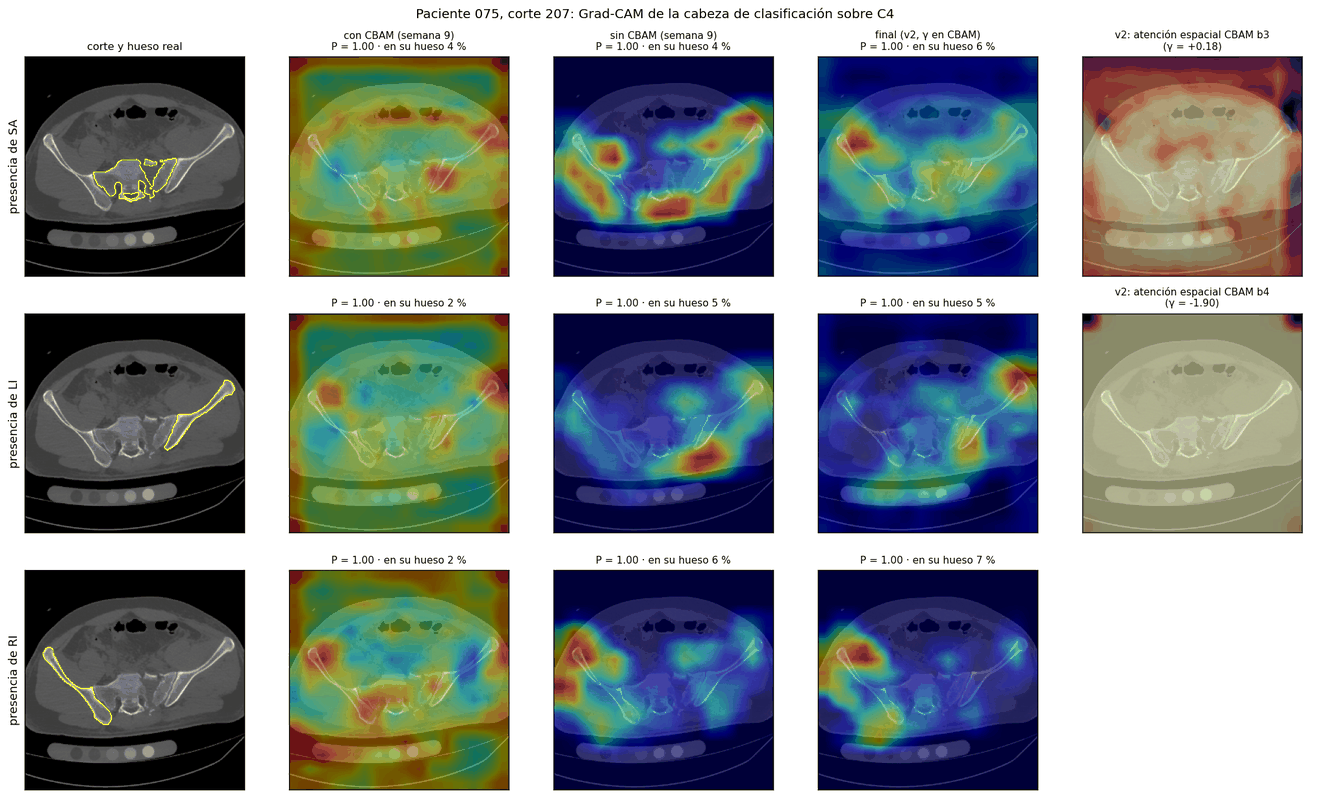

,P,masa en su hueso,masa en la pelvis
modelo,,,
base,1.0,0.027,0.080
sin_cbam,1.0,0.056,0.138
v2_last,1.0,0.063,0.133


M_s (media en hueso / media en fondo): {'075': (1.16, 1.0), '069': (1.2, 1.0), '019': (1.22, 1.0)}


In [15]:
display(Image(filename=str(FIG / "gradcam_075.png"), width=950))
gc = read_json(REP / "eval" / "gradcam.json")
filas = []
for cid, d in gc.items():
    for m in ("base", "sin_cbam", "v2_last"):
        for h, v in d[m].items():
            filas.append({"paciente": cid, "modelo": m, "hueso": h, "P": v["prob"], "masa en su hueso": v["masa_en_su_hueso"],
                          "masa en la pelvis": v["masa_en_pelvis"]})
g = pd.DataFrame(filas)
display(g.groupby("modelo")[["P", "masa en su hueso", "masa en la pelvis"]].mean().round(3))
print("M_s (media en hueso / media en fondo):", {c: (round(d["Ms_b3_hueso_vs_fondo"], 2), round(d["Ms_b4_hueso_vs_fondo"], 2)) for c, d in gc.items()})

- **La cabeza de clasificación no mira solo su hueso.** Solo el 2-8 % de la "masa" del Grad-CAM cae sobre el hueso que está clasificando, y 7-16 % sobre la pelvis. Decide la presencia con el contexto del corte entero: C4 tiene stride 16 y un campo receptivo que cubre casi toda la imagen, y la pregunta "¿hay sacro en este corte?" se contesta bien con la anatomía alrededor.
- **En los modelos de la semana 9, con CBAM el mapa es más difuso que sin CBAM** (2-4 % contra 4-7 % sobre su hueso). El modelo final, que también tiene CBAM, concentra más (5-8 %), así que esa diferencia no se puede atribuir solo al CBAM.
- **El mapa espacial $M_s$ del final casi no distingue hueso de fondo** (razón ≈ 1,2 en el bloque 3 y 1,0 en el 4), y el bloque 3 tiene γ ≈ 0,18: esa atención se usa poco. El bloque 4 tiene γ ≈ −1,9, es decir, la red invierte su atención.
- Junto con la ablación (sin CBAM, mismo resultado en CV y en test) la lectura es consistente: **en este problema el CBAM no aporta de forma medible**. Se mantiene porque el enunciado lo exige, y el γ permite mostrar cuánto lo usa la red en vez de suponerlo.

## 9. Afinado por etapas y EMA

Lo propuso el profesor el 9 de octubre: con el extractor y el detector ya entrenados, afinar solo la segmentación con el detector apagado, porque las tres pérdidas juntas interactúan. La regla de adopción se escribió **antes** de ver los resultados (`reports/tuning/S11_PREREGISTRO.md`):

- **`ftseg`:** 8 épocas más sobre cada modelo de CV (20 épocas), lr 1e-4, con backbone, cuello, clasificación y detección **congelados** (y su BatchNorm fijo).
- **`fttodo` (control):** lo mismo, pero entrenando todo. Separa "congelar" de "entrenar más".
- **EMA 0,999** en los dos; cada corrida guarda la media y el modelo sin promediar, así que EMA contra sin EMA sale emparejada dentro de la misma corrida.
- Todo con TTA 5 y el posproceso final fijo (`edt_hmax` 5 mm / 0,1 / h 1,5), contra la referencia con lo mismo.
- Se adopta solo con Δ Dice ≥ +0,026, t > 2,776, ≥ 4/5 folds, Δ IoU > 0 y el principal sin bajar más de 0,010.

In [16]:
PP = pd.read_csv(TUN / "ajuste_posproceso.csv.gz")
FIJO = "method == 'edt_hmax' and seed_depth_mm == 5 and edge_threshold == 0.1 and hmax_h_mm == 1.5"


def folds(exp):
    d = PP[PP.experimento == exp]
    if d.empty:
        return None
    d = d.query(FIJO) if "hmax_h_mm" in d and d.query(FIJO).shape[0] else d
    return d.groupby("fold")[["dice_fragmento", "iou_fragmento", "dice_principal", "recuperados_secundarios_%"]].mean()


ref = folds("pp_tta_base_hmax")
BRAZOS = {"ftseg (EMA)": "pp_s11_ftseg_last", "ftseg (sin EMA)": "pp_s11_ftseg_last_raw",
          "fttodo (EMA)": "pp_s11_fttodo_last", "fttodo (sin EMA)": "pp_s11_fttodo_last_raw"}


def comparar(a, b):
    dd = a.dice_fragmento - b.dice_fragmento
    n, sd = len(dd), dd.std(ddof=1)
    t = dd.mean() / (sd / np.sqrt(n)) if sd > 0 else np.nan
    di = (a.iou_fragmento - b.iou_fragmento).mean()
    dp = (a.dice_principal - b.dice_principal).mean()
    cumple = dd.mean() >= 0.026 and t > 2.776 and (dd > 0).sum() >= 4 and di > 0 and dp >= -0.010
    return {"Δ Dice": dd.mean(), "t": t, "folds a favor": f"{int((dd > 0).sum())}/{n}", "Δ IoU": di, "Δ principal": dp,
            "cumple la regla": "sí" if cumple else "no"}


R = {k: folds(v) for k, v in BRAZOS.items()}
if any(v is None for v in R.values()):
    print("Pendiente: el afinado por etapas todavía está corriendo en la DGX Spark.", {k: v is not None for k, v in R.items()})
else:
    filas = {"referencia (TTA 5 + F2C2)": {**ref.mean().to_dict()}}
    for k, v in R.items():
        filas[k] = {**v.mean().to_dict(), **comparar(v, ref)}
    s11 = pd.DataFrame(filas).T
    display(s11.round(4).fillna(""))
    print("ftseg contra fttodo (EMA):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in comparar(R["ftseg (EMA)"], R["fttodo (EMA)"]).items()})
    print("EMA contra sin EMA, ftseg: ", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in comparar(R["ftseg (EMA)"], R["ftseg (sin EMA)"]).items()})
    print("EMA contra sin EMA, fttodo:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in comparar(R["fttodo (EMA)"], R["fttodo (sin EMA)"]).items()})

,dice_fragmento,iou_fragmento,dice_principal,recuperados_secundarios_%,Δ Dice,t,folds a favor,Δ IoU,Δ principal,cumple la regla
referencia (TTA 5 + F2C2),0.792,0.717,0.914,67.898,,,,,,
ftseg (EMA),0.777,0.702,0.911,63.166,-0.015,-5.206,0/5,-0.015,-0.003,no
ftseg (sin EMA),0.777,0.701,0.911,63.530,-0.015,-5.106,0/5,-0.015,-0.003,no
fttodo (EMA),0.790,0.714,0.914,67.341,-0.002,-0.347,3/5,-0.003,-0.0,no
fttodo (sin EMA),0.790,0.714,0.913,67.806,-0.002,-0.319,3/5,-0.003,-0.001,no


ftseg contra fttodo (EMA): {'Δ Dice': np.float64(-0.0124), 't': np.float64(-1.8006), 'folds a favor': '1/5', 'Δ IoU': np.float64(-0.0126), 'Δ principal': np.float64(-0.0026), 'cumple la regla': 'no'}
EMA contra sin EMA, ftseg:  {'Δ Dice': np.float64(0.0), 't': np.float64(0.0151), 'folds a favor': '2/5', 'Δ IoU': np.float64(0.0002), 'Δ principal': np.float64(0.0003), 'cumple la regla': 'no'}
EMA contra sin EMA, fttodo: {'Δ Dice': np.float64(-0.0005), 't': np.float64(-0.3432), 'folds a favor': '3/5', 'Δ IoU': np.float64(0.0001), 'Δ principal': np.float64(0.0005), 'cumple la regla': 'no'}


**Resultado: ningún brazo cumple la regla.** El modelo final no cambia y el test no se volvió a mirar.

- **Congelar empeora.** Afinar solo la segmentación baja el Dice por fragmento 0,015 (t = −5,2, 0/5 folds). Entrenar todo el modelo las mismas 8 épocas queda igual (−0,002, t = −0,35). La caída viene del congelamiento, no de entrenar más: `ftseg` contra `fttodo`, −0,012 y 1/5 folds.
- **Por qué.** Con el backbone fijo, el decodificador solo puede bajar la pérdida de borde memorizando: en train baja de 0,223 a 0,208 y en validación sube de 0,424 a 0,429. Mejorar el borde exige cambiar las características compartidas, que es justo lo que el congelamiento impide. Además, aquí las tareas no compiten por el backbone: detección y región ya están saturadas y casi no sobreajustan (sección 8.2). Separarlas no libera capacidad para el borde.
- **EMA: sin efecto.** Δ 0,000 en `ftseg` y −0,0005 en `fttodo`, emparejado dentro de la misma corrida. No se adopta, así que la advertencia del profesor (que la EMA puede enmascarar si la entrada cambia) no aplica al modelo entregado: no promedia pesos.
- La sugerencia se probó con el mismo protocolo que todo lo demás (pre-registro, 5 folds, control) y queda documentada como descartada, con su razón.

## 10. Fuga de datos, sobreajuste e incertidumbre del test

Tres preguntas que conviene responder antes de creer un número de test: ¿el modelo vio de alguna forma a los pacientes de test?, ¿memoriza en vez de generalizar?, y ¿qué tan preciso es un resultado medido en 15 pacientes?

### 10.1 Fuga de datos

In [17]:
au = read_json(REP / "eval" / "auditoria.json")
p = au["huella_par_mas_parecido"]
print(f"{au['casos']} volúmenes · cabeceras idénticas (tamaño + spacing + origen): {au['cabeceras_identicas'] or 'ninguna'}")
print(f"Huella de imagen (MIP axial 32×32): par más parecido {p['casos']} ({' / '.join(p['particiones'])}), r = {p['correlacion']:.3f}")
print(f"Máxima correlación dentro de una misma partición {au['huella_max_misma_particion']:.3f} · entre particiones {au['huella_max_entre_particiones']:.3f} · "
      f"pares con r > 0,95: {au['huella_pares_sobre_0_95']}")

100 volúmenes · cabeceras idénticas (tamaño + spacing + origen): ninguna
Huella de imagen (MIP axial 32×32): par más parecido ['042', '078'] (train / train), r = 0.934
Máxima correlación dentro de una misma partición 0.934 · entre particiones 0.928 · pares con r > 0,95: 0


| Posible vía de fuga | Estado | Evidencia |
|---|---|---|
| Un mismo paciente en train y test | **no** | ninguna cabecera repetida; ningún par de volúmenes con r > 0,95 (arriba) |
| Cortes de un paciente repartidos entre particiones | **no** | partición y folds por paciente; con 2.5D, los cortes vecinos son casi iguales y esto sería grave |
| Preprocesado ajustado con la etiqueta | **no** | el recorte óseo usa solo la imagen; ventana fija |
| λ calibrados con validación o test | **no** | `calibrate_lambdas.py` usa train; en CV, los casos de train de cada fold |
| Transfer learning con datos médicos | **no** | pesos del Taller 3 (MVTec, tornillos) |
| Estadísticas del EDA sobre los 100 casos | **leve** | la ventana L400/W1800, los pesos de clase y el umbral óseo salieron del EDA, que incluyó los 15 de test. Son estadísticas globales de intensidad y frecuencia, no ajustes al resultado |
| Decisiones tomadas viendo el test | **leve, declarada** | la época entregada de `v2` y los diagnósticos que llevaron a separar por distancia (`02_semana10` §21). El ajuste posterior no miró el test |

Balancear la partición con el patrón de fractura de todos los casos no es fuga: estratificar con la etiqueta es práctica estándar y no ajusta el modelo.

### 10.2 Sobreajuste

| Dónde | Evidencia | Lectura |
|---|---|---|
| Detección y región | brecha train − val con la misma métrica: 0,054 mAP@[.50:.95], 0,023 IoU de caja, 0,005 Dice región (sección 8.2) | casi no sobreajustan |
| Cabeza de borde | pérdida 0,23 en train contra 0,43 en validación; el dropout de 0 a 0,40 no la cierra | **sobreajusta**: es la causa de fondo del Dice por fragmento |
| Selección entre ~60 variantes por CV | lo adoptado da 0,792 / 0,717 en CV medida en la grilla de 256 px; en la grilla nativa, la misma del test, 0,786 / 0,707; en test 0,768 / 0,697 | en la misma grilla el test sale 0,018 más bajo en Dice y 0,010 en IoU: compatible con el optimismo de quedarse con el ganador entre muchas. Se mitigó replicando TTA y F2C2 con una segunda semilla antes de adoptarlos |

### 10.3 Incertidumbre del test

El test tiene 15 pacientes. Para el intervalo de confianza se remuestrean **pacientes** con reemplazo (bootstrap, 5000 réplicas): los fragmentos de un mismo paciente no son independientes.

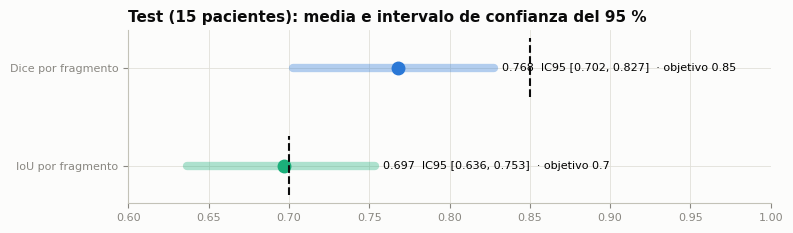

Fracción de réplicas con IoU ≥ 0,70: 0.48 · con Dice ≥ 0,85: 0.002


In [18]:
b = au["bootstrap"]
fig, ax = plt.subplots(figsize=(8, 2.4))
for y, (m, ic, obj, c) in enumerate(((b["iou"], b["iou_ic95"], 0.70, C["RI"]), (b["dice"], b["dice_ic95"], 0.85, C["SA"]))):
    ax.plot(ic, [y, y], color=c, lw=6, alpha=0.35, solid_capstyle="round")
    ax.plot(m, y, "o", color=c, ms=9)
    ax.plot([obj, obj], [y - 0.3, y + 0.3], color=INK, lw=1.5, ls="--")
    ax.text(ic[1] + 0.005, y, f"{m:.3f}  IC95 [{ic[0]:.3f}, {ic[1]:.3f}]  · objetivo {obj}", va="center", fontsize=8)
ax.set_yticks([0, 1], ["IoU por fragmento", "Dice por fragmento"])
ax.set_xlim(0.6, 1.0)
ax.set_title("Test (15 pacientes): media e intervalo de confianza del 95 %", loc="left")
fig.tight_layout()
savefig(fig, "ic_test")
plt.show()
print(f"Fracción de réplicas con IoU ≥ 0,70: {b['p_iou_mayor_igual_0_70']:.2f} · con Dice ≥ 0,85: {b['p_dice_mayor_igual_0_85']:.3f}")

- **IoU por fragmento 0,697, IC95 [0,636; 0,753].** El objetivo de 0,70 queda dentro del intervalo y la mitad de las réplicas lo supera: con 15 pacientes **no se puede afirmar ni que se cumple ni que no se cumple**. Lo correcto es reportarlo así, no como "casi cumple".
- **Dice por fragmento 0,768, IC95 [0,702; 0,827].** El 0,85 queda fuera del intervalo (0,2 % de las réplicas lo alcanza): ese objetivo no se cumple con este modelo.
- Clasificación y detección están tan por encima de sus objetivos que la incertidumbre no cambia la conclusión.

## 11. Decisiones de la semana y uso del test

| # | Intento | Evidencia | Decisión |
|---|---|---|---|
| 16 | Dashboard FastAPI propio en vez de Streamlit | subida por trozos, mismo código del pipeline, una sola página que funciona en celular | **adoptado** |
| 17 | Publicar por el VPS del equipo en vez de Cloudflare | el puerto 7844 de Cloudflare está bloqueado en la red de la DGX Spark | **adoptado**, declarado |
| 18 | Orientación oblicua por cosenos directores | ningún caso de PENGWIN la necesita; 3 tests con volúmenes sintéticos | **adoptado** (solo actúa si hace falta) |
| 19 | HD95 y ASSD por fragmento | métrica opcional del §5 | **reportado** |
| 20 | Afinado por etapas (`ftseg`) y EMA | sección 9 | descartados: congelar empeora (t = −5,2) y la EMA no cambia nada |
| 21 | Malla 3D con σ = 0,5 (antes 0,8) | sección 1.1 | **adoptado**: el dibujo dejaba de agrandar los huecos de hueso delgado; no toca ninguna métrica |
| 22 | L2 ×100, `weight_decay` 1e-2 (`c11_wd1e2`) | `04_semana11_borde` §3: Dice frag 0,683, z = 0,43 (umbral 0,696) | descartado en el cribado |
| 23 | Decodificador de 32 canales (`c12_segw32`) | `04_semana11_borde` §3: 0,690, z = 1,25 | descartado en el cribado |
| 24 | Decodificador U-Net++ (`c13_unetpp`) | `04_semana11_borde` §3: 0,693, z = 1,66 | descartado en el cribado |
| 25 | Cierre morfológico del hueco del ala ilíaca (`fill_holes_mm`, 1,5-7 mm) | sección 1.2: Δ Dice −0,0002 a −0,0035, 0/5 folds a favor | **descartado**: baja las métricas y no quita el hueco del 075 de la malla |

Uso del test en la semana 11: la misma `configs/tuned.yaml` se evaluó otra vez guardando las predicciones para la galería y añadiendo HD95/ASSD; da las mismas cifras a tres decimales (Dice 0,768, IoU 0,697) y no cambió nada del modelo. Como el afinado no cumplió la regla, el test no se volvió a medir.

Cierre de la semana: ningún candidato pasó el cribado, así que no hubo modelo nuevo ni otra medición de test.

## 12. Verificación contra el enunciado

In [19]:
ev = read_json(REP / "eval" / "v2_last_test.json")["metricas"]
req = [
    ("§2.2", "Distancias con el spacing del header, nunca en píxeles", "sí", "measurement/separation.py; EDT con sampling = spacing"),
    ("§2.1", "Taxonomía PENGWIN tal cual (SA, coxal izq., coxal der.; hasta 10 fragmentos)", "sí", "postprocess/instances.py"),
    ("§3.1", "Detección con cabeza propia y NMS propia", "sí", "detection/grid.py, detection/nms.py"),
    ("§3.2", "Máscara de instancia por fragmento, color por hueso, dos etapas", "sí", "región + borde → fragmentos (02_semana10 §1-4)"),
    ("§3.3", "Distancia mínima borde a borde con distance_transform_edt, también en el GT", "sí", "sección 6"),
    ("§3.4", "Visualizador 1: MIP del volumen crudo con umbral HU", "sí", "dashboard, pestaña 1"),
    ("§3.4", "Visualizador 2: corte a corte con slider, cajas y máscaras", "sí", "dashboard, pestaña 2"),
    ("§3.4", "Visualizador 3: marching cubes + Plotly Mesh3d", "sí", "dashboard, pestaña 3"),
    ("§3.4", "Distancia visible en los visualizadores 2 y 3", "sí", "etiqueta sobre cada secundario"),
    ("§4.1", "Backbone FundidoraPC extendido; TL solo en el backbone; cabezas desde cero", "sí", "models/backbone.py; checkpoints/fundidora_taller3.pth"),
    ("§4.1", "CBAM de canal y espacial antes de la bifurcación", "sí", "etapas 3 y 4 del backbone"),
    ("§4.1", "Tres cabezas sobre un mismo backbone", "sí", "models/pengwin_net.py; el ensamble se descartó por esto"),
    ("§4.1", "Pérdida multitarea con λ calibrados y justificados", "sí", "λ por norma de gradiente (reports/lambdas.json)"),
    ("§4.1", "Sin YOLO, Detectron2 ni Mask R-CNN", "sí", "todo propio en PyTorch"),
    ("§4.2", "SAM solo como línea base con la caja predicha como prompt", "sí", "scripts/sam_baseline.py; 02_semana10 §7"),
    ("§4.3", "256 px, batch 8, precisión mixta, CPU y GPU, latencia por imagen", "sí", "sección 3"),
    ("§5", "F1 ≥ 0,85", "sí" if ev["cls_f1_macro"] >= 0.85 else "no", f"{ev['cls_f1_macro']:.3f}"),
    ("§5", "AUC ≥ 0,85", "sí" if ev["cls_auc_macro"] >= 0.85 else "no", f"{ev['cls_auc_macro']:.3f}"),
    ("§5", "IoU de caja ≥ 0,65", "sí" if ev["IoU_promedio"] >= 0.65 else "no", f"{ev['IoU_promedio']:.3f}"),
    ("§5", "mAP@0.50 ≥ 0,65", "sí" if ev["mAP@0.50"] >= 0.65 else "no", f"{ev['mAP@0.50']:.3f}"),
    ("§5", "mAP@[.50:.95] ≥ 0,40", "sí" if ev["mAP@[.50:.95]"] >= 0.40 else "no", f"{ev['mAP@[.50:.95]']:.3f}"),
    ("§5", "Dice por fragmento ≥ 0,85", "sí" if G["dice_fragmento"] >= 0.85 else "no", f"{G['dice_fragmento']:.3f}"),
    ("§5", "IoU por fragmento ≥ 0,70", "no concluyente", f"{G['iou_fragmento']:.3f}, IC95 0,636-0,753 (sección 10.3)"),
    ("§5", "HD95 y ASSD (opcional)", "sí", f"{G['hd95_mm']:.1f} mm / {G['assd_mm']:.1f} mm"),
    ("§6-11", "Dashboard integrado y desplegado, accesible en computador y celular", "sí", "https://pengwin.80-241-217-130.nip.io (VPS, no Cloudflare: sección 1)"),
    ("§7", "Repositorio con historial y PR por integrante, main protegida", "equipo", "README, flujo de Git"),
    ("§7", "Pesos .pth y pipeline reproducible (requirements, semillas, comandos)", "sí", "README; pesos en GitHub Releases"),
    ("§7", "Model card por modelo, con contacto entre fragmentos y aviso no clínico", "sí", "reports/model_cards/"),
    ("§7", "Informe: ablación, matriz de confusión, 5 peores casos, distancia pred vs GT", "sí", "secciones 4-6; 02_semana10 §16"),
    ("§7", "IA_USAGE.md", "sí", "IA_USAGE.md, en la raíz del repositorio"),
    ("§7", "Pitch de 25 min y video de respaldo", "equipo", "demo en vivo con los casos de ejemplo"),
]
tabla = pd.DataFrame(req, columns=["§", "Requisito", "Cumple", "Dónde / valor"])
display(tabla.style.hide(axis="index"))

§,Requisito,Cumple,Dónde / valor
§2.2,"Distancias con el spacing del header, nunca en píxeles",sí,measurement/separation.py; EDT con sampling = spacing
§2.1,"Taxonomía PENGWIN tal cual (SA, coxal izq., coxal der.; hasta 10 fragmentos)",sí,postprocess/instances.py
§3.1,Detección con cabeza propia y NMS propia,sí,"detection/grid.py, detection/nms.py"
§3.2,"Máscara de instancia por fragmento, color por hueso, dos etapas",sí,región + borde → fragmentos (02_semana10 §1-4)
§3.3,"Distancia mínima borde a borde con distance_transform_edt, también en el GT",sí,sección 6
§3.4,Visualizador 1: MIP del volumen crudo con umbral HU,sí,"dashboard, pestaña 1"
§3.4,"Visualizador 2: corte a corte con slider, cajas y máscaras",sí,"dashboard, pestaña 2"
§3.4,Visualizador 3: marching cubes + Plotly Mesh3d,sí,"dashboard, pestaña 3"
§3.4,Distancia visible en los visualizadores 2 y 3,sí,etiqueta sobre cada secundario
§4.1,Backbone FundidoraPC extendido; TL solo en el backbone; cabezas desde cero,sí,models/backbone.py; checkpoints/fundidora_taller3.pth


**Cierre.** El sistema cumple todos los requisitos funcionales y de arquitectura, y cinco de las siete métricas del §5. El Dice por fragmento (0,768) no llega al 0,85; el IoU por fragmento (0,697, IC95 0,636-0,753) queda en el límite, y con 15 pacientes no se puede afirmar si cumple el 0,70 o no. La evidencia de las semanas 10 y 11 apunta a la misma causa: la cabeza de borde no marca la superficie de fractura entre fragmentos en contacto, y esos fragmentos se fusionan. En validación cruzada, con el borde real, el mismo pipeline llega a 0,90. Ningún hiperparámetro, ni el CBAM, ni el transfer learning lo movieron por encima del ruido de semilla; lo que sí funcionó fue reducir la varianza (TTA) y no perder semillas de fragmentos pequeños (F2C2). Todo el ajuste se eligió por validación cruzada; antes del ajuste, dos decisiones de la semana 10 miraron el test (la época entregada de `v2` y los diagnósticos que llevaron a separar por distancia) y están declaradas en `02_semana10` §21.